# Fit of the VCA with magnetic end springs

Fits a nonlinear model to the chirp data in `data/train` and `data/test`:

$$m\ddot{x} = \Gamma\, i - c\,\dot{x} - F_s(x)$$

| Symbol | Meaning | Initial guess |
|---|---|---|
| $m$ | moving mass | 51.5 kg (fixed) |
| $\Gamma$ | motor constant | 283 N/A (datasheet) |
| $c$ | viscous damping | NA |
| $C_\mu$ | magnet coupling constant | 2.423 N·m² (PDF eq. 13) |
| $g_0$ | magnet gap at centre | 22.3 mm (experiment, measured) |

**Strategy.** All fits are sequential, on two experiment types (Stage 0):
1. Stage 1: on the plain chirp at high frequency and low amplitude, the spring force is negligible; fit $\Gamma$ and $c$.
2. Method A: on the scheduled chirp from 10 Hz up to `F_MAX_A`, fit the spring with $\Gamma$, $c$ fixed from Stage 1: Method A a cubic polynomial, Method B an odd polynomial with a position-dependent $\Gamma(x)$, Method C two unequal repelling magnets.

**Discrete-time model.** RK4 with $T_s$ = 1 ms (log at 2 kHz, every other sample kept) and zero-order-hold input. Predictions start from the measured $(x, \dot{x})$; models are compared on position NRMSE against prediction horizon.

**Assumptions**
- Constant $\Gamma$ (PDF Assumption 1), no equilibrium offset.
- Input is `actual_current_A`; position is `position_mm` (converted in C), shifted back by `TAU` to align it with the current and notched at 50/150 Hz (mains pickup); the fits use the position-derived acceleration. The accelerometer (`ai2_corrected_V`, shifted by `TAU_ACC`) is only plotted for comparison.
- Current, position and acceleration are zero-phase low-pass filtered (4th-order Butterworth, 100 Hz) before decimation; the t < 0 idle window is dropped. $\dot{x}$ is the gradient of the filtered position.

In [1]:
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from scipy import signal
from scipy.optimize import least_squares

sns.set_theme(style="whitegrid")

FS_LOG, DECIM = 2000.0, 2
TS = 1/1000.0                       # discretization inter-sampling time
M = 51.5                            # kg
GAMMA0, C0 = 283.0, 1700.0          # datasheet; iteration
CMU0, G00 = 2.423, 22.3e-3          # PDF eq. 13; measured gap in experiment
s_ds = lambda x: (283 - 0.0198 * (x * 1e3) - 0.578 * (x * 1e3)**2) / 283   # datasheet K_f(z) shape, z in mm, 1 at the centre
LF_MAX, HF_MIN = 5.0, 37.0          # Hz; Low freq range and high freq range, ub and lb (37 Hz: above the 35.5 Hz laser-mount mode)
H_FIT, H_EVAL, STRIDE = 500, 500, 10 # steps for fitting the data
FOH = False                         # Zero-order hold
TAU = 0.65e-3                       # s, position is logged this much later than current; undone in load
TAU_ACC = 2.65e-3                   # s, accelerometer is logged this much later than current; undone in load
T_CUT = 5.0                         # s, end of each run left out of the HF band
ACC_SCALE_V_PER_G = 0.0578 * 0.65   # accelerometer V/g: plot-script 0.0578 corrected by the gain against position above 35 Hz (0.60-0.68)
F_MAX_A = 55.0                      # Hz, Methods A-C use the scheduled chirp up to this frequency (55 = whole run; 34 stays below the 35.5 Hz mode)

b_lp, a_lp = signal.butter(4, 100.0 / (FS_LOG / 2))   # 4th-order 100 Hz low-pass


def load(path):
    "Read one log; return filtered current, position and acceleration at 1 kHz (t >= 0), velocity, and band masks."
    # chirp start/end frequency and duration from the file name, e.g. ..._1.0to55.0Hz_120.0s_...
    m = re.search(r"_([\d.]+)to([\d.]+)Hz_([\d.]+)s_", path.name)
    f0, f1, T = map(float, m.groups()) if m else (np.nan,) * 3   # no chirp in the name (e.g. PRBS): band masks are empty
    raw = np.loadtxt(path, delimiter=",", skiprows=2)   # skip header and the duplicate first row
    lp = lambda s: signal.filtfilt(b_lp, a_lp, s)       # zero-phase, also the anti-alias filter for decimation
    # columns 0 time_s, 1 actual_current_A, 11 position_mm, 12 ai2_corrected_V (bias removed in firmware)
    t = raw[:, 0]
    x = np.interp(t + TAU, t, lp(raw[:, 11] * 1e-3))   # shift position back by TAU to align it with the current
    for f_n in (50.0, 150.0):                           # mains pickup in the laser signal
        x = signal.filtfilt(*signal.iirnotch(f_n, 30.0, fs=FS_LOG), x)
    a = (np.interp(t + TAU_ACC, t, lp(raw[:, 12])) / ACC_SCALE_V_PER_G * 9.81 if raw.shape[1] > 12   # measured acceleration, shifted back by TAU_ACC
         else np.full(len(t), np.nan))                          # older logs have no ai2_corrected_V
    keep = slice(np.searchsorted(t, 0.0), None, DECIM)  # drop the t < 0 idle window, 2 kHz -> 1 kHz
    d = dict(t=t[keep], i=lp(raw[:, 1])[keep], x=x[keep], a_meas=a[keep])
    d["v"] = np.gradient(d["x"], TS)                    # velocity: initial states and LLS
    d["a_x"] = np.gradient(d["v"], TS)                  # acceleration from position
    d["a"] = d["a_x"]                                   # fits use position-derived acceleration; accelerometer only plotted
    f = f0 * (f1 / f0) ** (d["t"] / T)                  # instantaneous frequency of the exponential chirp
    d["lf"] = f <= LF_MAX                               # old low band, used by methods B-D
    d["hf"] = (f >= HF_MIN) & (d["t"] <= d["t"][-1] - T_CUT)
    d["sweep"] = f <= F_MAX_A                           # Methods A-C window: scheduled chirp from its start up to F_MAX_A
    return d


def step(x, v, u0, u1, acc):
    "One RK4 step of (x, v) with input u0 at the start and u1 at the end of the step."
    um = 0.5 * (u0 + u1)
    k1x, k1v = v, acc(x, v, u0)
    k2x, k2v = v + TS / 2 * k1v, acc(x + TS / 2 * k1x, v + TS / 2 * k1v, um)
    k3x, k3v = v + TS / 2 * k2v, acc(x + TS / 2 * k2x, v + TS / 2 * k2v, um)
    k4x, k4v = v + TS * k3v, acc(x + TS * k3x, v + TS * k3v, u1)
    return x + TS / 6 * (k1x + 2 * k2x + 2 * k3x + k4x), v + TS / 6 * (k1v + 2 * k2v + 2 * k3v + k4v)


def rollout(Fs, p, d, s, H):
    "Predicted x, shape (len(s), H+1), from the measured state at each start index s. p = [Gamma, c, *spring]."
    acc = lambda x, v, u: (p[0] * u - p[1] * v - Fs(x, u, p[2:])) / M      # Fs gets the current too, for Gamma(x)
    x, v, out = d["x"][s], d["v"][s], [d["x"][s]]
    with np.errstate(all="ignore"):
        for k in range(H):
            u0 = d["i"][s + k]
            x, v = step(x, v, u0, d["i"][s + k + 1] if FOH else u0, acc)
            out.append(x)
    return np.stack(out, axis=1)


def starts(d, band, H):
    "Every STRIDE-th sample of the band whose H-step horizon fits in the record."
    s = np.flatnonzero(band)[::STRIDE]
    return s[s + H < len(d["x"])]


def target(d, s, H):
    "Measured x over the horizon of each start, shape (len(s), H+1)."
    return d["x"][s[:, None] + np.arange(H + 1)]


def fit(Fs, p0, d, band, lb=-np.inf, free=slice(None), detrend=False):
    "H-step-ahead fit of p0[free]; detrend removes per-start mean and slope of the error (free-mass drift)."
    s = starts(d, band, H_FIT)
    X = target(d, s, H_FIT)[:, 1:]
    p = np.array(p0, float)
    def res(q):
        p[free] = q
        e = np.nan_to_num(rollout(Fs, p, d, s, H_FIT)[:, 1:], nan=1.0, posinf=1.0, neginf=-1.0) - X   # diverged rollout -> 1 m
        return (signal.detrend(e, axis=1) if detrend else e).ravel()
    r = least_squares(res, p[free], x_scale=np.abs(p[free]), bounds=(lb, np.inf))
    p[free] = r.x
    print(f"{r.message} ({r.nfev} evaluations)")
    return p


def nrmse_curve(Fs, p, d, band, H=H_EVAL):
    "Position RMS error per horizon step, normalised by the std of x in the band."
    s = starts(d, band, H)
    e = rollout(Fs, p, d, s, H) - target(d, s, H)
    return np.sqrt(np.mean(e ** 2, axis=0)) / np.std(d["x"][band])


CURVES = []

def evaluate(name, Fs, p, exp, band, H=H_EVAL):
    "Left: NRMSE against horizon, train and test. Right: one H-step prediction on test, started mid-band."
    fig, ax = plt.subplots(1, 2, figsize=(15, 4))
    k = np.arange(1, H + 1)
    for split, d in DATA[exp].items():
        e = nrmse_curve(Fs, p, d, d[band], H)[1:]
        CURVES.append(dict(method=name, split=split, exp=exp, band=band, k=k, nrmse=e))   # kept for the comparison cell
        sns.lineplot(x=k, y=e, ax=ax[0], label=split)
        print(f"{split:5s} NRMSE at k = 1, 10, 100, {H}: " + ", ".join(f"{e[j - 1]:.3f}" for j in (1, 10, 100, H)))
    ax[0].set(xscale="log", xlabel="steps ahead (1 step = 1 ms)", ylabel="position NRMSE", title=f"{name}, {band.upper()} band")
    d = DATA[exp]["test"]
    s0 = starts(d, d[band], H)
    s0 = s0[len(s0) // 2:][:1]                          # one start in the middle of the band
    t = d["t"][s0[0]:s0[0] + H + 1]
    sns.lineplot(x=t, y=target(d, s0, H)[0] * 1e3, ax=ax[1], label="measured", color="k")
    sns.lineplot(x=t, y=rollout(Fs, p, d, s0, H)[0] * 1e3, ax=ax[1], label="predicted")
    ax[1].set(xlabel="time (s)", ylabel="x (mm)", title=f"test: {H}-step prediction from the measured state")
    plt.tight_layout(); plt.show()


# self-check: undamped linear spring from x = 1 mm must follow cos(wt)
_k = 1e5
_d = dict(x=np.full(2, 1e-3), v=np.zeros(2), i=np.zeros(1000))
_x = rollout(lambda x, u, q: q[0] * x, [0.0, 0.0, _k], _d, np.array([0]), 900)[0]
assert np.allclose(_x, 1e-3 * np.cos(np.sqrt(_k / M) * TS * np.arange(901)), atol=1e-8)

## Stage 0: data

Two experiment types per split, from `data/train` and `data/test`:
- `chirp`: plain chirp, 1→55 Hz, for Stage 1 (band `hf`: ≥ `HF_MIN` Hz, last `T_CUT` s cut).
- `chirpsched`: chirp 10→55 Hz with amplitude ramps, for Method A (band `sweep`: from the start up to `F_MAX_A` Hz).

The 3 s idle window (t < 0) is dropped; position is notched at 50 and 150 Hz (mains pickup in the laser). The fits use the position-derived acceleration; the bias-corrected accelerometer `ai2_corrected_V` is only plotted for comparison.

chirp      train a_meas / a_from_x = 1.142
chirp      test  a_meas / a_from_x = 1.106
chirpsched train a_meas / a_from_x = 1.225
chirpsched test  a_meas / a_from_x = 1.242


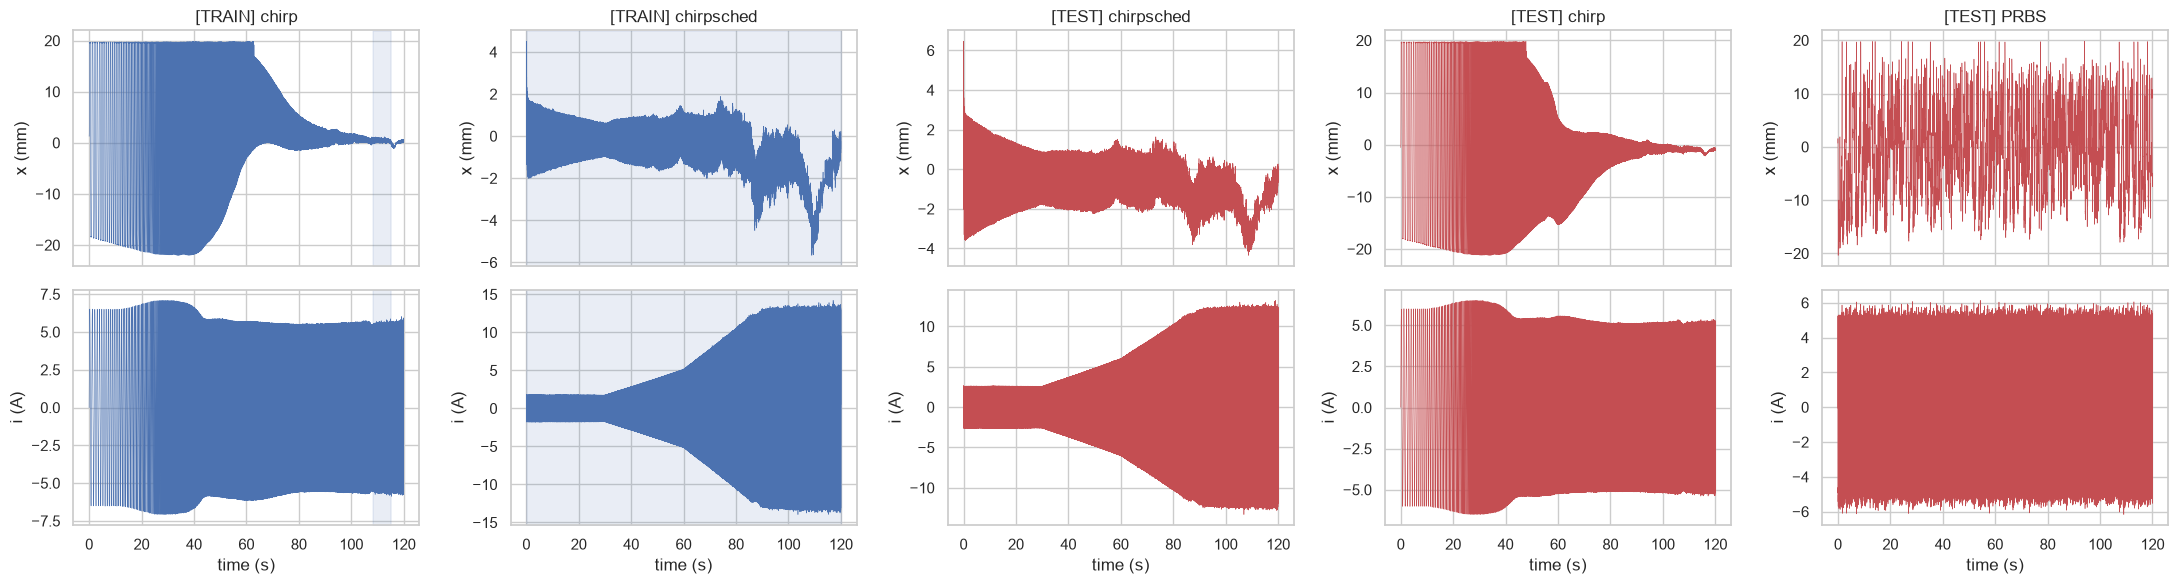

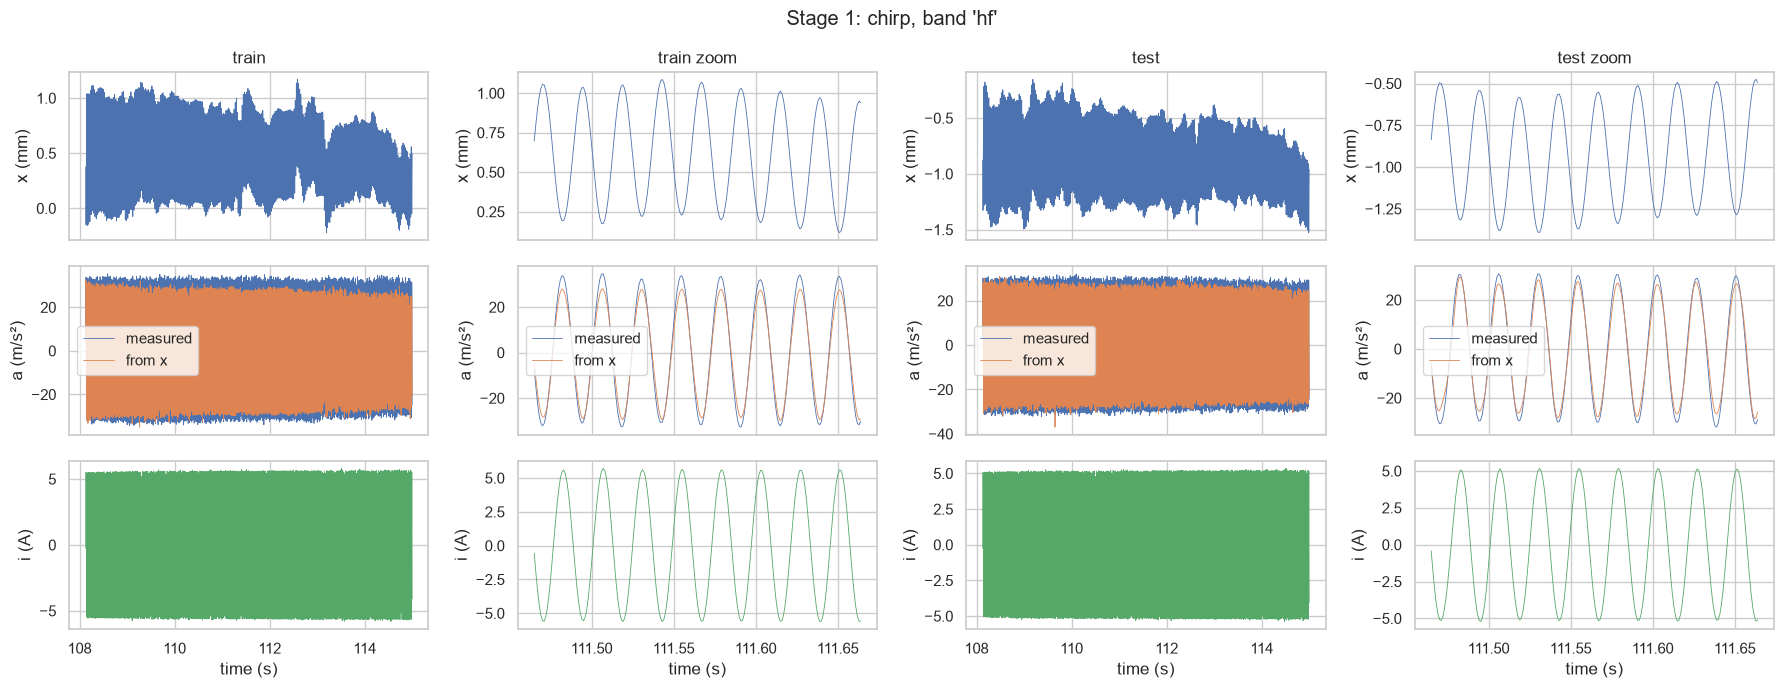

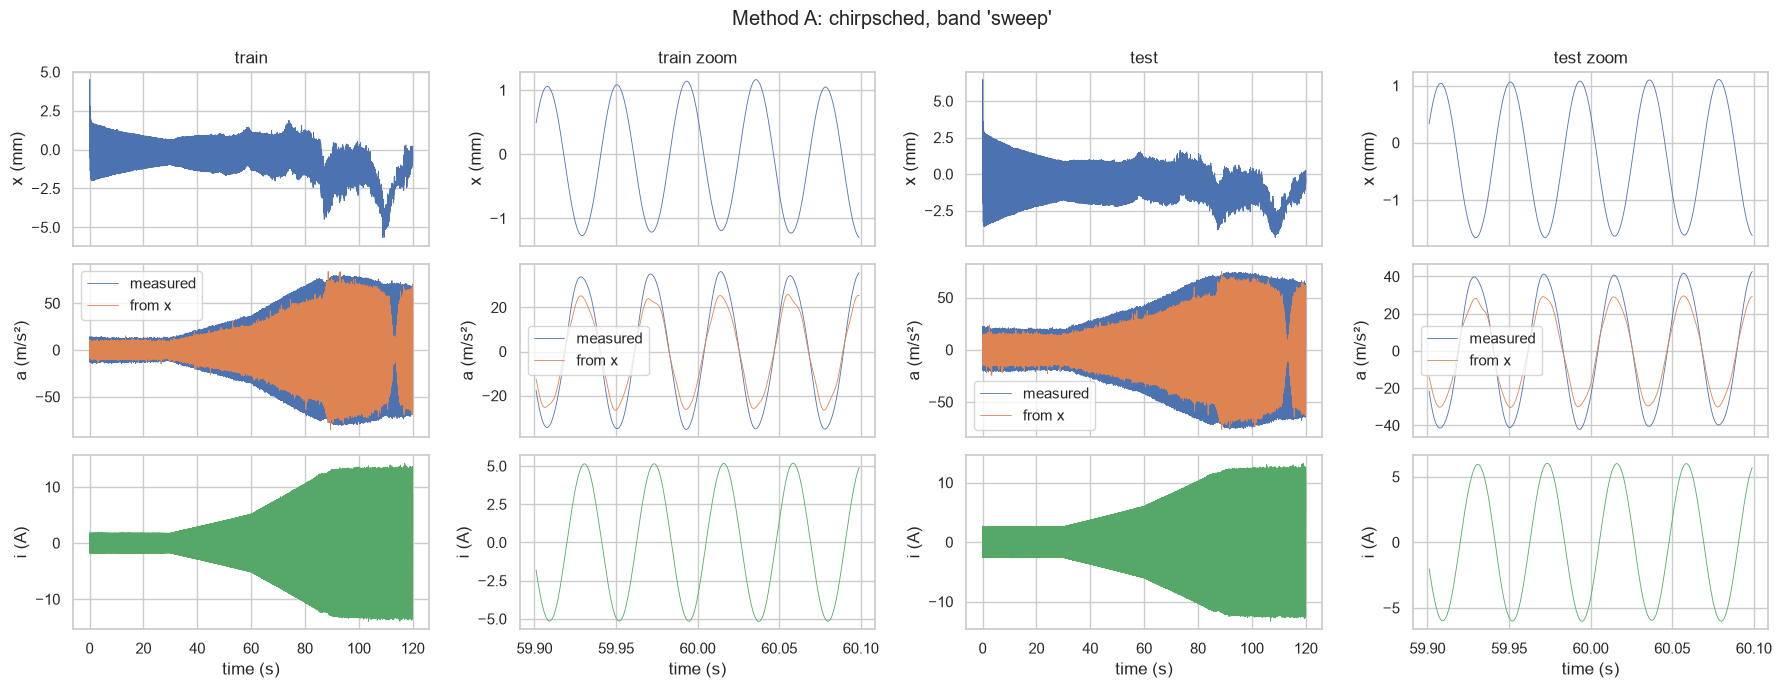

In [2]:
DATA = {exp: {s: load(next(Path("data", s).glob(f"voice_coil_log_{exp}_*.csv"))) for s in ("train", "test")}
        for exp in ("chirp", "chirpsched")}
USE = [("Stage 1", "chirp", "hf"), ("Method A", "chirpsched", "sweep")]

# accelerometer scale check: slope of measured against position-derived acceleration, 1.0 if ACC_SCALE_V_PER_G is right
for exp, runs in DATA.items():
    for split, d in runs.items():
        m = d["hf"] | d["sweep"] if exp == "chirpsched" else d["hf"]
        print(f"{exp:10s} {split:5s} a_meas / a_from_x = {np.polyfit(d['a_x'][m], d['a_meas'][m], 1)[0]:.3f}")

# overview: position (top) and current (bottom) of every run, TRAIN in blue, TEST in red; shaded: the window the fit uses
SETS = [("TRAIN", "chirp", DATA["chirp"]["train"], "hf"),            # (role, name, data, band used by the fit): Stage 1
        ("TRAIN", "chirpsched", DATA["chirpsched"]["train"], "sweep"),  # Methods A-C
        ("TEST", "chirpsched", DATA["chirpsched"]["test"], None),       # validation, Kalman filter
        ("TEST", "chirp", DATA["chirp"]["test"], None),                 # validation, Kalman filter
        ("TEST", "PRBS", load(next(Path("data").glob("voice_coil_log_prbs_*.csv"))), None)]   # validation (23 Sep, +-16 mm: extrapolation)
fig, ax = plt.subplots(2, len(SETS), figsize=(22, 6), sharex="col")
for col, (role, name, d, band) in enumerate(SETS):
    color = "C0" if role == "TRAIN" else "C3"
    sns.lineplot(x=d["t"], y=d["x"] * 1e3, ax=ax[0, col], lw=0.4, color=color).set(title=f"[{role}] {name}", ylabel="x (mm)")
    sns.lineplot(x=d["t"], y=d["i"], ax=ax[1, col], lw=0.4, color=color).set(xlabel="time (s)", ylabel="i (A)")
    if band:
        for a_ in ax[:, col]:
            a_.fill_between(d["t"], 0, 1, where=d[band], transform=a_.get_xaxis_transform(), color=color, alpha=0.12)
plt.tight_layout(); plt.show()

# data actually used, one figure per fit: rows position, acceleration, current;
# columns train (whole window, zoom), test (whole window, zoom). The zoom shows a few cycles mid-window to judge delays.
ZOOM_S = 0.2                                            # s, length of the zoom window
for stage, exp, band in USE:
    fig, ax = plt.subplots(3, 4, figsize=(18, 7), sharex="col")
    for k, (split, d) in enumerate(DATA[exp].items()):
        idx = np.flatnonzero(d[band])
        t_mid = d["t"][idx[len(idx) // 2]]
        for col, m in [(2 * k, d[band]), (2 * k + 1, d[band] & (np.abs(d["t"] - t_mid) <= ZOOM_S / 2))]:
            t = d["t"][m]
            sns.lineplot(x=t, y=d["x"][m] * 1e3, ax=ax[0, col], lw=0.6).set(title=f"{split}{' zoom' if col % 2 else ''}", ylabel="x (mm)")
            sns.lineplot(x=t, y=d["a_meas"][m], ax=ax[1, col], lw=0.6, label="measured")
            sns.lineplot(x=t, y=d["a_x"][m], ax=ax[1, col], lw=0.6, label="from x").set(ylabel="a (m/s²)")
            sns.lineplot(x=t, y=d["i"][m], ax=ax[2, col], lw=0.6, color="C2").set(xlabel="time (s)", ylabel="i (A)")
    fig.suptitle(f"{stage}: {exp}, band '{band}'"); plt.tight_layout(); plt.show()

## Spectral analysis of the plain chirp (raw position)

Raw position of the plain chirp only (`SPLIT` = train or test), read straight from the CSV at the logged 2 kHz (Nyquist 1 kHz): no low-pass, no 50/150 Hz notch, no delay shift, no decimation. Shown up to `F_SHOW` = 300 Hz. Left: spectrogram (short-time Fourier transform, Hann window), frequency against time, which should show the chirp's rising line. Right: Welch PSD (averaged FFT periodograms) in dB.

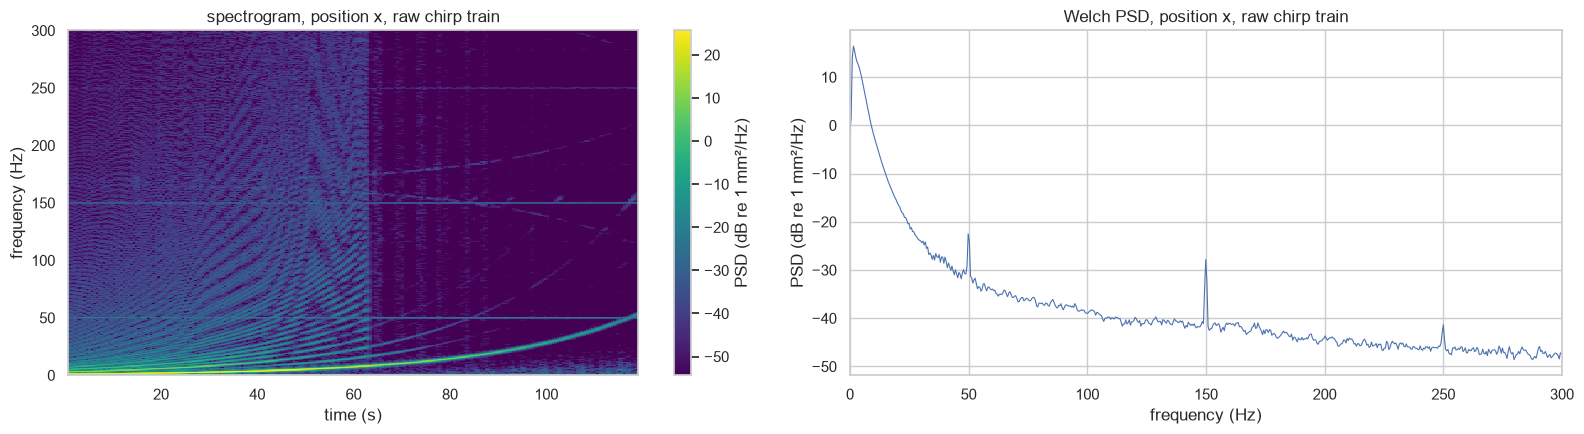

In [3]:
SPLIT = "train"                                         # "train" or "test"
NFFT = 4096                                             # samples per segment: 2.05 s at 2 kHz, 0.49 Hz resolution
F_SHOW = 300.0                                          # Hz, upper plot limit (Nyquist of the raw log is 1 kHz)
path = next(Path("data", SPLIT).glob("voice_coil_log_chirp_*.csv"))   # plain chirp only (chirpsched_ does not match)
raw = np.loadtxt(path, delimiter=",", skiprows=2)       # raw 2 kHz log: no low-pass, no notch, no delay shift, no decimation
x_raw = raw[raw[:, 0] >= 0.0, 11]                       # position_mm, t < 0 idle window dropped

fig, ax = plt.subplots(1, 2, figsize=(16, 4.5))
f, t, S = signal.spectrogram(x_raw, fs=FS_LOG, window="hann", nperseg=NFFT, noverlap=NFFT * 3 // 4, detrend="constant", scaling="density")
S_db = 10 * np.log10(S[f <= F_SHOW] + 1e-20)            # colour scale from the shown band only
im = ax[0].pcolormesh(t, f[f <= F_SHOW], S_db, shading="auto", cmap="viridis", vmin=S_db.max() - 80, vmax=S_db.max())
ax[0].set(ylim=(0, F_SHOW), xlabel="time (s)", ylabel="frequency (Hz)", title=f"spectrogram, position x, raw chirp {SPLIT}")
fig.colorbar(im, ax=ax[0], label="PSD (dB re 1 mm²/Hz)")
f, P = signal.welch(x_raw, fs=FS_LOG, window="hann", nperseg=NFFT, noverlap=NFFT // 2, detrend="constant", scaling="density")
sns.lineplot(x=f[f <= F_SHOW], y=10 * np.log10(P[f <= F_SHOW] + 1e-20), ax=ax[1], lw=0.8)   # y-axis autoscales to the shown band
ax[1].set(xlim=(0, F_SHOW), xlabel="frequency (Hz)", ylabel="PSD (dB re 1 mm²/Hz)", title=f"Welch PSD, position x, raw chirp {SPLIT}")
plt.tight_layout(); plt.show()

## Stage 1: motor constant (HF, plain chirp)

Plain chirp, band `hf`: ≥ `HF_MIN` Hz with the last `T_CUT` s cut. We fit $\Gamma$ and $c$ by bounded linear least squares (`lsq_linear`, $c \geq 0$), optionally with a linear spring $k\,x$ (`SPRING`):

$$m\ddot{x} = \Gamma\, i - c\,\dot{x}\;[-\,k\,x]$$

In [4]:
from scipy.optimize import lsq_linear

SPRING = False                                          # add a linear spring k x to Stage 1
d, sel = DATA["chirp"]["train"], DATA["chirp"]["train"]["hf"]
cols = {"Gamma": d["i"], "c": -d["v"]}                  # m a = Gamma i - c v [- k x]
if SPRING:
    cols["k"] = -d["x"]
A = np.column_stack(list(cols.values()))[sel]
lb = [0.0 if n == "c" else -np.inf for n in cols]       # c >= 0
p_hf = lsq_linear(A, M * d["a"][sel], bounds=(lb, np.inf)).x
print(", ".join(f"{n} = {val:.4g}" for n, val in zip(cols, p_hf)))
stage1_force = lambda x, u, q: q[0] * x if SPRING else 0.0 * x

Gamma = 260.8, c = 1126


Prediction with the fitted Stage 1 terms (without a spring the model is a free mass and drifts):

$$m\ddot{x} = \Gamma\, i - c\,\dot{x}\;[-\,k\,x]$$

train NRMSE at k = 1, 10, 100, 600: 0.003, 0.326, 1.743, 4.798
test  NRMSE at k = 1, 10, 100, 600: 0.003, 0.367, 1.729, 3.379


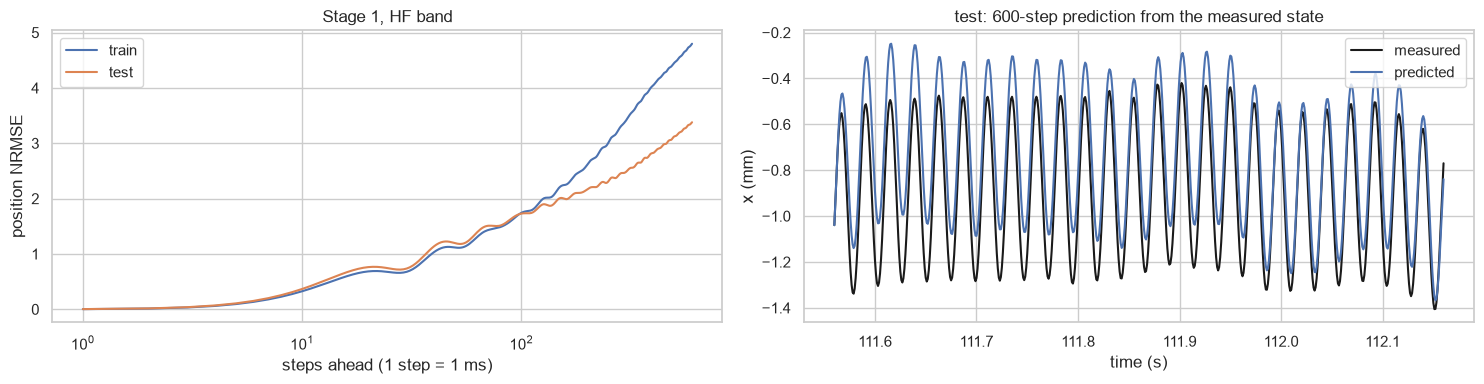

In [5]:
evaluate("Stage 1", stage1_force, p_hf, "chirp", "hf", H=600)

## Method A: cubic spring, LLS

Polynomial spring with an even term for asymmetry, fitted by bounded linear least squares on the scheduled chirp up to `F_MAX_A` Hz. Each row is divided by the local current amplitude, so the high-current end does not dominate.

$$m\ddot{x} = (\Gamma\,+\,\Gamma_1 x)\, i - c\,\dot{x} - (k_1 x + k_2 x^2 + k_3 x^3)$$

Options (set in the first line of the cell):
- `FREE_GC = False`: $\Gamma$ and $c$ are fixed at the Stage 1 values.
- `FREE_GC = True`: $\Gamma$ and $c$ are refitted here, together with the spring ($c \geq 0$).
- `GAMMA_X = False`: constant motor constant $\Gamma$.
- `GAMMA_X = True`: position-dependent motor constant $\Gamma(x) = \Gamma + \Gamma_1 x$.

Always: $k_3 \geq 0$, so the spring hardens with stroke and keeps its restoring force outside the fitted range.

In [6]:
FREE_GC, GAMMA_X = True, True                           # refit Gamma and c here; position-dependent Gamma(x) = Gamma + Gamma1 x
poly3 = lambda x, u, q: q[-3] * x + q[-2] * x**2 + q[-1] * x**3 - (q[0] * x * u if GAMMA_X else 0.0)   # q = [Gamma1,] k1, k2, k3
d, sel = DATA["chirpsched"]["train"], DATA["chirpsched"]["train"]["sweep"]
x, i, v = d["x"][sel], d["i"][sel], d["v"][sel]
w = 1 / np.abs(signal.hilbert(d["i"]))[sel]                          # 1 / current amplitude, so every part of the sweep counts about equally
cols = {"k1": -x, "k2": -x**2, "k3": -x**3}                         # m a = Gamma i - c v [+ Gamma1 x i] - (k1 x + k2 x^2 + k3 x^3)
if GAMMA_X:
    cols = {"Gamma1": x * i, **cols}
if FREE_GC:
    cols = {"Gamma": i, "c": -v, **cols}
y = M * d["a"][sel] if FREE_GC else M * d["a"][sel] - p_hf[0] * i + p_hf[1] * v   # fixed Gamma, c (Stage 1) moved to the left
A = np.column_stack(list(cols.values()))
lb = [0.0 if n in ("c", "k3") else -np.inf for n in cols]           # c >= 0; k3 >= 0: hardening spring
sc = np.linalg.norm(A * w[:, None], axis=0)                          # column scaling
q = dict(zip(cols, lsq_linear(A * w[:, None] / sc, y * w, bounds=(lb, np.inf)).x / sc))
G, c = (q.pop("Gamma"), q.pop("c")) if FREE_GC else p_hf[:2]
p_p3 = np.r_[G, c, list(q.values())]
print(f"Gamma = {G:.1f} N/A, c = {c:.1f} N s/m ({'fitted here' if FREE_GC else 'Stage 1'}); " + ", ".join(f"{n} = {val:.4g}" for n, val in q.items()))
if GAMMA_X:
    print("Gamma(x)/Gamma at -5, +5 mm: " + ", ".join(f"{1 + q['Gamma1'] * xx / G:.3f}" for xx in (-5e-3, 5e-3)))

Gamma = 235.3 N/A, c = 2133.5 N s/m (fitted here); Gamma1 = 6536, k1 = 5.856e+04, k2 = -9.707e+05, k3 = 6.624e-20
Gamma(x)/Gamma at -5, +5 mm: 0.861, 1.139


train NRMSE at k = 1, 10, 100, 1000: 0.003, 0.195, 0.773, 0.713
test  NRMSE at k = 1, 10, 100, 1000: 0.003, 0.180, 0.642, 0.594


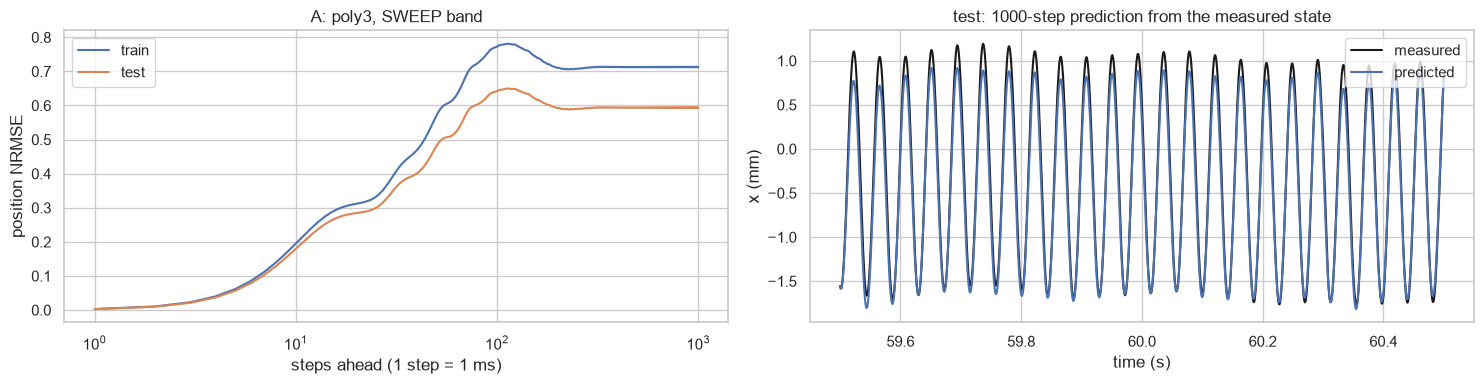

In [7]:
evaluate("A: poly3", poly3, p_p3, "chirpsched", "sweep", H=1000)

## Method B: cubic spring with the datasheet motor constant shape, LLS

Method A's model, but the motor constant follows the shape of the actuator datasheet curve, $K_f(z) = 283 - 0.0198\,z - 0.578\,z^2$ (N/A, $z$ in mm). Only its scale $\Gamma_0$ is fitted, so the motor term cannot take over the role of the spring. Same data and weighting as Method A.

$$m\ddot{x} = \Gamma_0\, s(x)\, i - c\,\dot{x} - (k_1 x + k_2 x^2 + k_3 x^3), \qquad s(x) = \frac{K_f(x)}{283} \;(= 1 \text{ at the centre})$$

Options (set in the first line of the cell):
- `FREE_GC = False`: $\Gamma_0$ and $c$ are fixed at the Stage 1 values.
- `FREE_GC = True`: $\Gamma_0$ and $c$ are refitted here, together with the spring ($c \geq 0$).

Always: the datasheet shape $s(x)$, and $k_3 \geq 0$, so the spring hardens with stroke.

In [8]:
FREE_GC = True                                          # refit Gamma0 and c here; False: Stage 1 values
d, sel = DATA["chirpsched"]["train"], DATA["chirpsched"]["train"]["sweep"]
x, i, v = d["x"][sel], d["i"][sel], d["v"][sel]
w = 1 / np.abs(signal.hilbert(d["i"]))[sel]                          # 1 / current amplitude, so every part of the sweep counts about equally
cols = {"k1": -x, "k2": -x**2, "k3": -x**3}                         # m a = Gamma0 s(x) i - c v - (k1 x + k2 x^2 + k3 x^3)
if FREE_GC:
    cols = {"Gamma0": i * s_ds(x), "c": -v, **cols}
y = M * d["a"][sel] if FREE_GC else M * d["a"][sel] - p_hf[0] * s_ds(x) * i + p_hf[1] * v   # fixed Gamma0, c (Stage 1) moved to the left
A = np.column_stack(list(cols.values()))
lb = [0.0 if n in ("c", "k3") else -np.inf for n in cols]           # c >= 0; k3 >= 0: hardening spring
sc = np.linalg.norm(A * w[:, None], axis=0)                          # column scaling
q = dict(zip(cols, lsq_linear(A * w[:, None] / sc, y * w, bounds=(lb, np.inf)).x / sc))
G0, c = (q.pop("Gamma0"), q.pop("c")) if FREE_GC else p_hf[:2]
p_B = np.r_[G0, c, list(q.values())]
poly3_ds = lambda x, u, q, G0=G0: q[0] * x + q[1] * x**2 + q[2] * x**3 + G0 * (1 - s_ds(x)) * u   # spring, plus Gamma0 (1 - s(x)) i so the motor force is Gamma0 s(x) i
print(f"Gamma0 = {G0:.1f} N/A, c = {c:.1f} N s/m ({'fitted here' if FREE_GC else 'Stage 1'}); " + ", ".join(f"{n} = {val:.4g}" for n, val in q.items()))
print("Gamma(x)/Gamma0 at -5, +5 mm (datasheet shape): " + ", ".join(f"{s_ds(xx):.3f}" for xx in (-5e-3, 5e-3)))

Gamma0 = 231.0 N/A, c = 2104.9 N s/m (fitted here); k1 = 6.426e+04, k2 = 5.401e+06, k3 = 3.635e-21
Gamma(x)/Gamma0 at -5, +5 mm (datasheet shape): 0.949, 0.949


train NRMSE at k = 1, 10, 100, 1000: 0.003, 0.199, 0.892, 0.900
test  NRMSE at k = 1, 10, 100, 1000: 0.003, 0.183, 0.803, 0.783


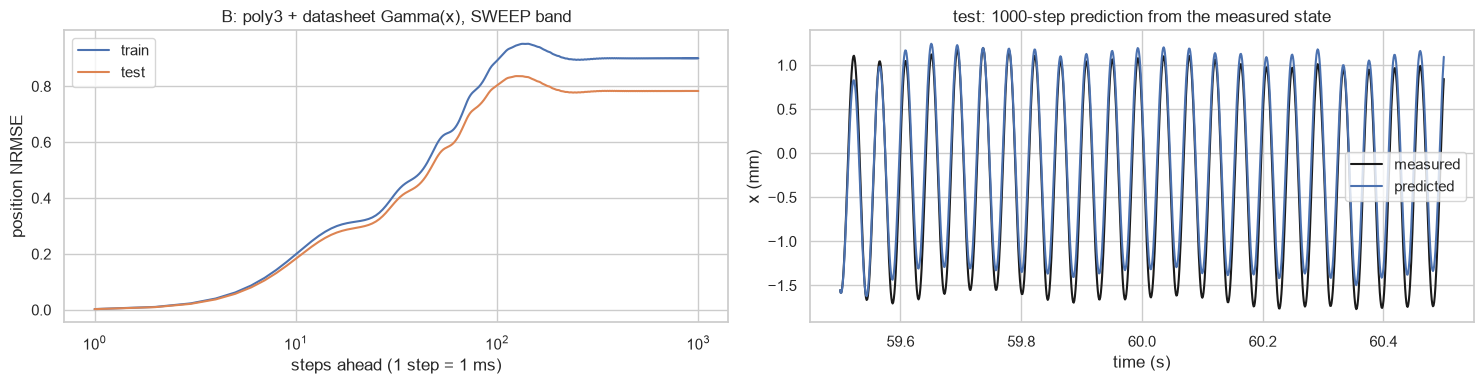

In [9]:
evaluate("B: poly3 + datasheet Gamma(x)", poly3_ds, p_B, "chirpsched", "sweep", H=1000)

## Method C: unequal magnets with a position-dependent motor constant, LLS

Two repelling magnets with their own strength, $C_R, C_L \geq 0$ (PDF eq. 3 with $Q_R \neq Q_L$): each always repels, and the net spring always restores and stiffens with stroke. $C_R \neq C_L$ gives the asymmetry. The gap is fixed at the measured $g_0$ = `G00` = 22.3 mm, so the model is linear in $C_R, C_L$. The motor constant is linear in position, $\Gamma(x) = \Gamma + \Gamma_1 x$, as in Method A, with $\Gamma_1$ fitted. Same data and weighting as Method A.

$$m\ddot{x} = (\Gamma + \Gamma_1 x)\, i - c\,\dot{x} - \left(\frac{C_R}{(g_0 - x)^2} - \frac{C_L}{(g_0 + x)^2}\right)$$

Options (set in the first line of the cell):
- `FREE_GC = False`: $\Gamma$ and $c$ are fixed at the Stage 1 values.
- `FREE_GC = True`: $\Gamma$ and $c$ are refitted here, together with $\Gamma_1$, $C_R$, $C_L$ ($c \geq 0$).

Always: $\Gamma(x) = \Gamma + \Gamma_1 x$, $g_0$ = 22.3 mm, and $C_R, C_L \geq 0$.

In [10]:
FREE_GC = True                                          # refit Gamma and c here; False: Stage 1 values
d, sel = DATA["chirpsched"]["train"], DATA["chirpsched"]["train"]["sweep"]
x, i, v = d["x"][sel], d["i"][sel], d["v"][sel]
w = 1 / np.abs(signal.hilbert(d["i"]))[sel]                          # 1 / current amplitude, so every part of the sweep counts about equally
cols = {"Gamma1": x * i, "C_R": -1 / (G00 - x)**2, "C_L": 1 / (G00 + x)**2}   # m a = (Gamma + Gamma1 x) i - c v - (C_R / (g0 - x)^2 - C_L / (g0 + x)^2)
if FREE_GC:
    cols = {"Gamma": i, "c": -v, **cols}
y = M * d["a"][sel] if FREE_GC else M * d["a"][sel] - p_hf[0] * i + p_hf[1] * v   # fixed Gamma, c (Stage 1) moved to the left
A = np.column_stack(list(cols.values()))
lb = [-np.inf if n in ("Gamma", "Gamma1") else 0.0 for n in cols]   # c, C_R, C_L >= 0
sc = np.linalg.norm(A * w[:, None], axis=0)                          # column scaling
q = dict(zip(cols, lsq_linear(A * w[:, None] / sc, y * w, bounds=(lb, np.inf)).x / sc))
G, c = (q.pop("Gamma"), q.pop("c")) if FREE_GC else p_hf[:2]
G1, C_R, C_L = q["Gamma1"], q["C_R"], q["C_L"]
p_C = np.r_[G, c, G1, C_R, C_L]
magnets = lambda x, u, q: q[1] / (G00 - x)**2 - q[2] / (G00 + x)**2 - q[0] * x * u   # magnets, minus Gamma1 x i so the motor force is (Gamma + Gamma1 x) i
print(f"Gamma = {G:.1f} N/A, c = {c:.1f} N s/m ({'fitted here' if FREE_GC else 'Stage 1'}); Gamma1 = {G1:.4g} N/(A m); C_R = {C_R:.4g} N m^2, C_L = {C_L:.4g} N m^2 "
      f"(C_R / C_L = {C_R / C_L:.3f}; PDF guess C_mu = {CMU0} N m^2)")
print(f"stiffness at x = 0: {2 * (C_R + C_L) / G00**3:.3g} N/m, force at x = 0: {(C_R - C_L) / G00**2:.3g} N")
print("Gamma(x)/Gamma at -5, +5 mm: " + ", ".join(f"{1 + G1 * xx / G:.3f}" for xx in (-5e-3, 5e-3)))

Gamma = 234.0 N/A, c = 2123.7 N s/m (fitted here); Gamma1 = 5548 N/(A m); C_R = 0.1689 N m^2, C_L = 0.1665 N m^2 (C_R / C_L = 1.015; PDF guess C_mu = 2.423 N m^2)
stiffness at x = 0: 6.05e+04 N/m, force at x = 0: 4.94 N
Gamma(x)/Gamma at -5, +5 mm: 0.881, 1.119


train NRMSE at k = 1, 10, 100, 1000: 0.003, 0.196, 0.781, 0.715
test  NRMSE at k = 1, 10, 100, 1000: 0.003, 0.180, 0.640, 0.587


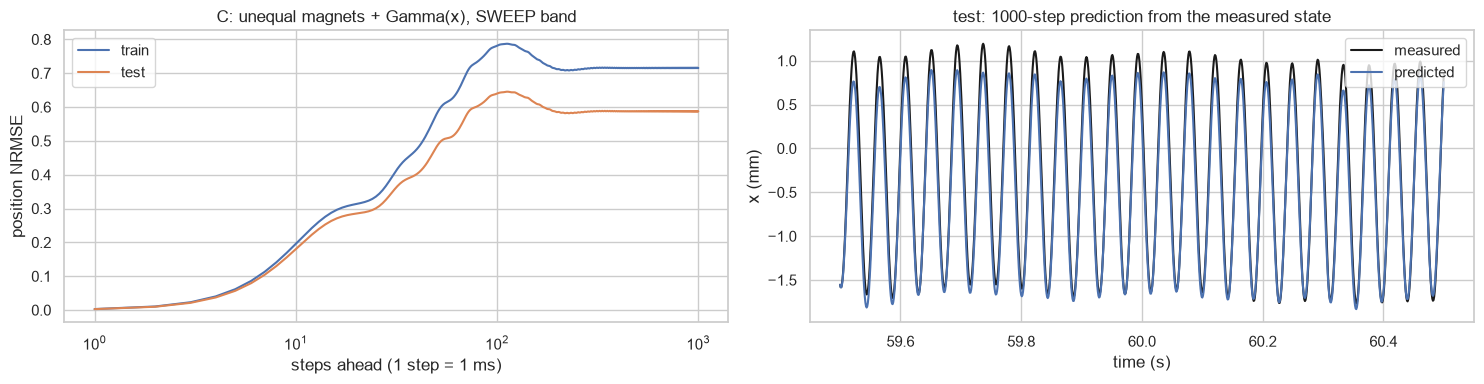

In [11]:
evaluate("C: unequal magnets + Gamma(x)", magnets, p_C, "chirpsched", "sweep", H=1000)

## Why Model D: what Model C leaves unexplained

The moving mass runs on an **air bearing** with nothing attached, so sliding (Coulomb) friction is not expected; the dissipation is air-film shear and eddy currents. Before choosing Model D's terms, this section looks at the force that Model C does not explain on the scheduled chirp (sweep band):

$$r_k = m\,\ddot{x}_k - \left[(\Gamma + \Gamma_1 x_k)\, i_k - c\,\dot{x}_k - \left(\frac{C_R}{(g_0 - x_k)^2} - \frac{C_L}{(g_0 + x_k)^2}\right)\right]$$

**1. Missing damping per frequency band.** The chirp frequency at time $t$ is $f(t) = f_0\,(f_1/f_0)^{t/T}$. In each 5 Hz band, the least-squares slope of $r$ against $\dot{x}$ is the damping Model C still lacks there:

$$\hat{c}_\Delta(f) = -\frac{\sum_k r_k\,\dot{x}_k}{\sum_k \dot{x}_k^2}, \qquad c_\text{eff}(f) = c + \hat{c}_\Delta(f)$$

If viscous damping were the whole story, $c_\text{eff}(f)$ would be flat at $c$.

**2. Two explanations, each with its own shape in $f$.**

- *Eddy-current damping* (a dissipation, caused by motion). A conductive loop with resistance $R_e$ and inductance $L_e$ moving through the magnet field sees the emf $B\ell\,\dot{x}$:
$$L_e\,\dot{i}_e + R_e\, i_e = B\ell\,\dot{x}, \quad F_e = B\ell\, i_e \;\Rightarrow\; \frac{F_e}{\dot{x}}(j\omega) = \frac{c_e}{1 + j\omega\tau_e}, \qquad c_e = \frac{(B\ell)^2}{R_e},\; \tau_e = \frac{L_e}{R_e}$$
Its dissipative (real) part $\dfrac{c_e}{1 + (\omega\tau_e)^2}$ falls with frequency and levels off at zero.

- *Force lag* (**not friction**: actuator or timing). If the force follows the logged current with a delay $\tau$,
$$\Gamma\, i(t - \tau) = \Gamma\, i(t) - \Gamma\tau\,\frac{di}{dt} + \mathcal{O}(\tau^2)$$
Above the spring resonance $f_n = \frac{1}{2\pi}\sqrt{k/m}$, $k = 2(C_R + C_L)/g_0^3$ (printed below), the mass line dominates, $m\ddot{x} \approx \Gamma i$. For $i = I\sin\omega t$ this gives $\dot{x} \approx -\frac{\Gamma I}{m\omega}\cos\omega t$ and $\frac{di}{dt} = \omega I\cos\omega t \approx -\frac{m\omega^2}{\Gamma}\,\dot{x}$, so
$$-\Gamma\tau\,\frac{di}{dt} \approx m\omega^2\tau\,\dot{x} \quad\Longleftrightarrow\quad c_\text{lag}(\omega) = -\,m\,\omega^2\,\tau$$
a negative damping that grows with $\omega^2$ and does not level off.

The cell fits both shapes to $c_\text{eff}(f)$ of the train bands: $c_\text{eff} = c_0 - m\omega^2\tau$ (linear in $c_0, \tau$) and $c_\text{eff} = \dfrac{c_e}{1 + (\omega\tau_e)^2}$.

**3. Coulomb step.** A Coulomb force $F_c\,\mathrm{sign}(\dot{x})$ would leave a jump in the mean residual at zero velocity:
$$\bar{r}(0^+) - \bar{r}(0^-) = -2F_c$$
estimated from the mean of $r$ in thin velocity slices either side of zero.

**4. Free-shape velocity curve.** The mean residual at a given velocity, as a sum of hat functions $\phi_j$ on evenly spaced knots:
$$\mathbb{E}[\,r \mid \dot{x}\,] \approx \sum_j w_j\,\phi_j(\dot{x})$$
Large $|\dot{x}|$ only occurs at high frequency, so velocity and frequency are confounded in this data. The curve is therefore fitted separately for $f < 25$ Hz and $f > 35$ Hz: if the two groups have different slopes at the same $\dot{x}$, the missing force depends on frequency, not on velocity.

Caveat: bands near the 35.5 Hz laser-mount mode also carry its error in the position-derived acceleration.

Model C: c = 2124 N s/m; spring resonance f_n = 5.5 Hz (the sweep starts at 10 Hz)

 band (Hz) | train: std r (N) c_eff (N s/m) | test: std r (N) c_eff (N s/m)
  10-15    |               92          2640 |             107          1800
  15-20    |               91          2051 |             107          1629
  20-25    |              128          1346 |             165          1158
  25-30    |              244           837 |             251           787
  30-35    |              289          1302 |             272          1344
  35-40    |              561           641 |             510           666
  40-45    |              475             3 |             439            41
  45-50    |              738           122 |             698           118
  50-55    |              795          -344 |             752          -455

force lag:   c_eff = c0 - m w^2 tau,       c0 = 2182 N s/m, tau = 0.493 ms;  rms misfit 356 N s/m
eddy damping: c_eff = c_e / (1 + (w tau_e)^2), c_e = 5365

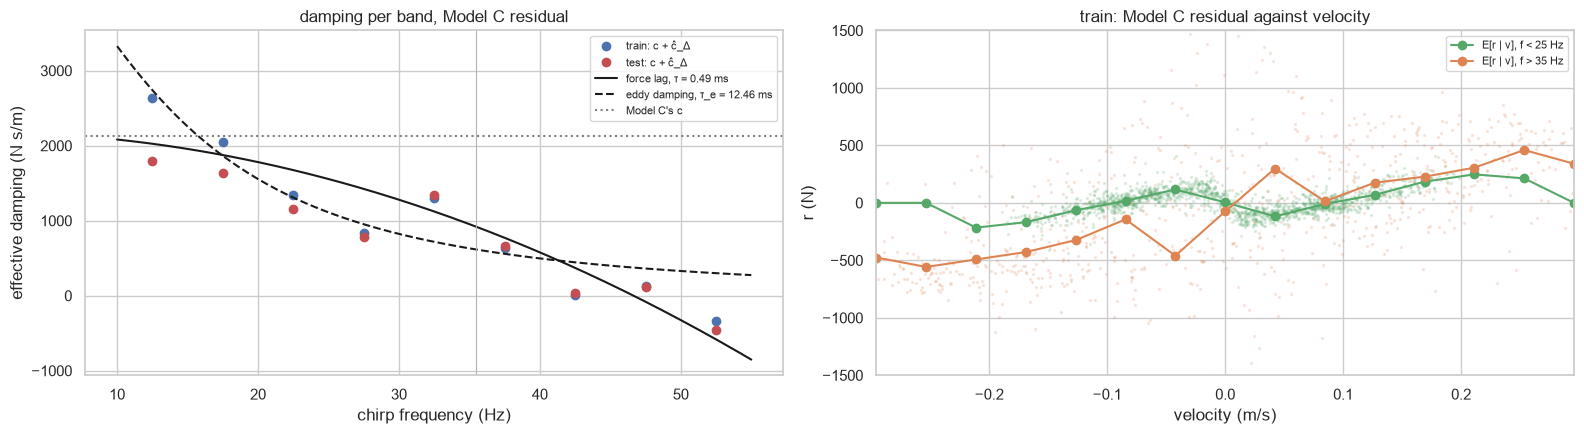

In [12]:
from scipy.optimize import curve_fit

F_EDGES = np.arange(10.0, 56.0, 5.0)                    # Hz, band edges for the per-band damping
V_SLICE = 0.01                                          # m/s, width of the slices either side of v = 0 (Coulomb step)
N_KNOTS = 15                                            # knots of the free-shape velocity curve


def chirp_freq(split, exp="chirpsched"):
    "Instantaneous chirp frequency of each sample of DATA[exp][split], from the file name as in load()."
    path = next(Path("data", split).glob(f"voice_coil_log_{exp}_*.csv"))
    f0, f1, T = map(float, re.search(r"_([\d.]+)to([\d.]+)Hz_([\d.]+)s_", path.name).groups())
    return f0 * (f1 / f0) ** (DATA[exp][split]["t"] / T)


def residual_C(d):
    "Force Model C leaves unexplained, r = m a - model C (N), on every sample."
    return M * d["a"] - (p_C[0] * d["i"] - p_C[1] * d["v"] - magnets(d["x"], d["i"], p_C[2:]))


def hat_basis(v, knots):
    "Piecewise-linear hat functions on the knots (constant beyond the end knots), one column per knot."
    return np.column_stack([np.interp(v, knots, e) for e in np.eye(len(knots))])


k_C = 2 * (p_C[3] + p_C[4]) / G00**3                    # magnet stiffness at x = 0
print(f"Model C: c = {p_C[1]:.0f} N s/m; spring resonance f_n = {np.sqrt(k_C / M) / (2 * np.pi):.1f} Hz (the sweep starts at 10 Hz)")

# 1. missing damping per frequency band, train and test
BANDS = {}
print(f"\n{'band (Hz)':>10s} | {'train: std r (N)':>16s} {'c_eff (N s/m)':>13s} | {'test: std r (N)':>15s} {'c_eff (N s/m)':>13s}")
for lo, hi in zip(F_EDGES[:-1], F_EDGES[1:]):
    row = []
    for split in ("train", "test"):
        d = DATA["chirpsched"][split]
        f, r = chirp_freq(split), residual_C(d)
        m = d["sweep"] & (f >= lo) & (f < hi)
        c_delta = -np.sum(r[m] * d["v"][m]) / np.sum(d["v"][m] ** 2)
        BANDS.setdefault(split, []).append((0.5 * (lo + hi), np.std(r[m]), p_C[1] + c_delta))
        row += [np.std(r[m]), p_C[1] + c_delta]
    print(f"{lo:4.0f}-{hi:<5.0f} | {row[0]:16.0f} {row[1]:13.0f} | {row[2]:15.0f} {row[3]:13.0f}")
BANDS = {s: np.array(b) for s, b in BANDS.items()}      # columns: band centre f, std r, c_eff

# 2. fit the two shapes to the train bands
fc, c_eff = BANDS["train"][:, 0], BANDS["train"][:, 2]
w_c = 2 * np.pi * fc
(c0_lag, tau_lag), *_ = np.linalg.lstsq(np.column_stack([np.ones_like(w_c), -M * w_c**2]), c_eff, rcond=None)
eddy = lambda w, c_e, tau_e: c_e / (1 + (w * tau_e) ** 2)
(c_e, tau_e), _ = curve_fit(eddy, w_c, c_eff, p0=(c_eff.max(), 1e-3), bounds=(0, np.inf))
rms_fit = lambda pred: np.sqrt(np.mean((c_eff - pred) ** 2))
print(f"\nforce lag:   c_eff = c0 - m w^2 tau,       c0 = {c0_lag:.0f} N s/m, tau = {tau_lag * 1e3:.3f} ms;  rms misfit {rms_fit(c0_lag - M * w_c**2 * tau_lag):.0f} N s/m")
print(f"eddy damping: c_eff = c_e / (1 + (w tau_e)^2), c_e = {c_e:.0f} N s/m, tau_e = {tau_e * 1e3:.3f} ms;  rms misfit {rms_fit(eddy(w_c, c_e, tau_e)):.0f} N s/m")

# 3. Coulomb step: mean residual just above minus just below v = 0 equals -2 F_c
for split in ("train", "test"):
    d = DATA["chirpsched"][split]
    r, v = residual_C(d)[d["sweep"]], d["v"][d["sweep"]]
    up, dn = r[(v > 0) & (v < V_SLICE)], r[(v < 0) & (v > -V_SLICE)]
    jump = up.mean() - dn.mean()
    se = np.sqrt(up.var() / len(up) + dn.var() / len(dn))   # naive: samples are correlated, the real uncertainty is larger
    print(f"[{split:5s}] Coulomb step r(0+) - r(0-) = {jump:+.1f} N (+-{se:.1f} N naive std err) -> F_c = {-jump / 2:+.1f} N")

# figure: c_eff per band with both fits (left), free-shape velocity curves per frequency group (right)
fig, ax = plt.subplots(1, 2, figsize=(16, 4.5))
for split, color in (("train", "C0"), ("test", "C3")):
    ax[0].plot(BANDS[split][:, 0], BANDS[split][:, 2], "o", color=color, label=f"{split}: c + ĉ_Δ")
fg = np.linspace(F_EDGES[0], F_EDGES[-1], 200)
ax[0].plot(fg, c0_lag - M * (2 * np.pi * fg) ** 2 * tau_lag, "k-", label=f"force lag, τ = {tau_lag * 1e3:.2f} ms")
ax[0].plot(fg, eddy(2 * np.pi * fg, c_e, tau_e), "k--", label=f"eddy damping, τ_e = {tau_e * 1e3:.2f} ms")
ax[0].axhline(p_C[1], color="0.5", ls=":", label="Model C's c")
ax[0].axvline(35.5, color="0.7", lw=0.8)
ax[0].set(xlabel="chirp frequency (Hz)", ylabel="effective damping (N s/m)", title="damping per band, Model C residual")
ax[0].legend(fontsize=8)
d, f = DATA["chirpsched"]["train"], chirp_freq("train")
r = residual_C(d)
v_max = np.percentile(np.abs(d["v"][d["sweep"]]), 99)
knots = np.linspace(-v_max, v_max, N_KNOTS)
for name, m, color in (("f < 25 Hz", d["sweep"] & (f < 25), "C2"), ("f > 35 Hz", d["sweep"] & (f > 35), "C1")):
    w_hat, *_ = np.linalg.lstsq(hat_basis(d["v"][m], knots), r[m], rcond=None)
    ax[1].scatter(d["v"][m][::40], r[m][::40], s=2, alpha=0.15, color=color)
    ax[1].plot(knots, w_hat, "o-", color=color, label=f"E[r | v], {name}")
ax[1].set(xlim=(-v_max, v_max), ylim=(-1500, 1500), xlabel="velocity (m/s)", ylabel="r (N)", title="train: Model C residual against velocity")
ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

## Model D: Model C with better dissipation, LLS

Model D keeps Model C's motor, $\Gamma(x)$ and magnets, and replaces the single viscous damper by a set of candidate dissipation terms. All parameters are refitted jointly:

$$m\ddot{x} = (\Gamma + \Gamma_1 x)\, i \;-\; \underbrace{\Gamma\tau\,\frac{di}{dt}}_{\text{force lag}} \;-\; \underbrace{(c + c_1 x + c_2 x^2)\,\dot{x}}_{c(x)} \;-\; \underbrace{c_q\,\dot{x}|\dot{x}|}_{\text{quadratic}} \;-\; \underbrace{\left(F_c + F_{st}\, e^{-(\dot{x}/v_{st})^2}\right)\tanh\frac{\dot{x}}{v_c}}_{\text{Coulomb + Stribeck}} \;-\; \left(\frac{C_R}{(g_0 - x)^2} - \frac{C_L}{(g_0 + x)^2}\right)$$

| Term | Physical picture | Parameters |
|---|---|---|
| force lag | **not friction**: current-induced eddy currents, the drive's current loop, or a logging misalignment; a nuisance term so the damping terms are not biased by it | $\Gamma\tau$, with $\tau = \Gamma\tau / \Gamma$ |
| $c(x)$ | air-film or eddy damping that changes along the stroke | $c, c_1, c_2$ |
| quadratic | damping that grows (or saturates, $c_q < 0$) with speed | $c_q$ |
| Coulomb + Stribeck | sliding friction with a stiction peak; on an air bearing a **null check**, expected $\approx 0$ | $F_c, F_{st}$ |

The force lag $\tau$ cannot be told apart from a leftover alignment error between the logged current and position: shifting the position log by $\delta$ changes the fitted $\tau$ by about $\delta$. It is therefore not interpreted here.

**Linear in the parameters.** With $v_c$ and $v_{st}$ fixed, every term is a known regressor times one coefficient:

$$m\ddot{x}_k = \varphi\!\left(x_k, \dot{x}_k, i_k, \tfrac{di}{dt}\big|_k\right)^{\!\top} \theta$$

fitted by the same weighted, bounded least squares as Methods A–C, with $W = \mathrm{diag}\big(1/|\mathcal{H}\{i\}|\big)$ the inverse current amplitude (Hilbert envelope):

$$\hat{\theta} = \arg\min_{\theta \,\geq\, \theta_{lb}} \left\| W\left(\Phi\,\theta - m\ddot{x}\right) \right\|^2, \qquad c,\, C_R,\, C_L,\, F_c,\, F_{st} \geq 0$$

$\Gamma\tau$, $c_1$, $c_2$, $c_q$ are free: their sign is part of the answer. $\tanh(\dot{x}/v_c)$ is a smooth $\mathrm{sign}(\dot{x})$; $v_c$ and $v_{st}$ are picked from a small grid by the lowest weighted cost.

**Variants**

| Variant | Terms added to Model C |
|---|---|
| D0 | force lag |
| D1 | $c(x)$, quadratic |
| D2 | Coulomb + Stribeck (null check) |
| D-full | all of the above |

**Simulation.** `rollout_D` is `rollout` with a force that also depends on $\dot{x}$ and $\frac{di}{dt}$. $\frac{di}{dt}$ is the gradient of the filtered current, held constant over each RK4 step like the current itself (zero-order hold).

In [13]:
BASE = ["Gamma", "c", "Gamma1", "C_R", "C_L"]          # Model C's parameters, in the order of p_C
LB0 = ("c", "C_R", "C_L", "F_c", "F_st")                # physically non-negative; all others free
V_C_GRID = [0.002, 0.005, 0.01, 0.02, 0.05]             # m/s, smoothing velocity of the Coulomb sign
V_ST_GRID = [0.01, 0.02, 0.05, 0.1]                     # m/s, Stribeck decay velocity
VARIANTS = {"D0": BASE + ["Gtau"],
            "D1": BASE + ["c1", "c2", "cq"],
            "D2": BASE + ["F_c", "F_st"],
            "D-full": BASE + ["Gtau", "c1", "c2", "cq", "F_c", "F_st"]}
LABELS = {"D0": "D0: C + force lag", "D1": "D1: C + c(x) + v|v|", "D2": "D2: C + Coulomb/Stribeck", "D-full": "D-full: all terms"}


def regressors(x, v, i, di, v_c, v_st):
    "Every candidate term of m a = phi' theta: the column that multiplies its coefficient, keyed by parameter name."
    sgn = np.tanh(v / v_c)                              # smooth sign(v)
    return {"Gamma": i, "c": -v, "Gamma1": x * i,
            "C_R": -1 / (G00 - x)**2, "C_L": 1 / (G00 + x)**2,
            "Gtau": -di,                                # force lag: Gamma i(t - tau) ~ Gamma i - Gamma tau di/dt
            "c1": -x * v, "c2": -x**2 * v,              # c(x) = c + c1 x + c2 x^2
            "cq": -v * np.abs(v),                       # quadratic damping
            "F_c": -sgn,                                # Coulomb
            "F_st": -np.exp(-(v / v_st)**2) * sgn}      # Stribeck peak on top of Coulomb


def design(d, sel, names, v_c, v_st):
    "Regressor matrix of the named terms on the samples sel."
    cols = regressors(d["x"][sel], d["v"][sel], d["i"][sel], np.gradient(d["i"], TS)[sel], v_c, v_st)
    return np.column_stack([cols[n] for n in names])


def fit_D(names, v_c, v_st):
    "Weighted bounded LLS on the train sweep, as Method C. Returns theta (in the order of names) and the weighted cost."
    d, sel = DATA["chirpsched"]["train"], DATA["chirpsched"]["train"]["sweep"]
    A, y = design(d, sel, names, v_c, v_st), M * d["a"][sel]
    w = 1 / np.abs(signal.hilbert(d["i"]))[sel]        # 1 / current amplitude, as in Methods A-C
    lb = [0.0 if n in LB0 else -np.inf for n in names]
    sc = np.linalg.norm(A * w[:, None], axis=0)         # column scaling
    r = lsq_linear(A * w[:, None] / sc, y * w, bounds=(lb, np.inf))
    return r.x / sc, 2 * r.cost


def fit_variant(names):
    "Fit; when Coulomb is in, take v_c and v_st from the grid with the lowest weighted cost."
    grid = [(a, b) for a in V_C_GRID for b in V_ST_GRID] if "F_c" in names else [(V_C_GRID[2], V_ST_GRID[2])]
    v_c, v_st = min(grid, key=lambda g: fit_D(names, *g)[1])
    return fit_D(names, v_c, v_st)[0], v_c, v_st


def force_D(names, v_c, v_st):
    "Force function Fs(x, v, u, du, q) for rollout_D, q = p[2:]: everything except Gamma u - c v, so m a = Gamma u - c v - Fs."
    def Fs(x, v, u, du, q):
        cols = regressors(x, v, u, du, v_c, v_st)
        return -sum(qj * cols[n] for n, qj in zip(names[2:], q))
    return Fs


def rollout_D(Fs, p, d, s, H):
    "As rollout, but the force also gets the velocity and di/dt: Fs(x, v, u, du, q)."
    di = np.gradient(d["i"], TS)
    x, v, out = d["x"][s], d["v"][s], [d["x"][s]]
    with np.errstate(all="ignore"):
        for k in range(H):
            u0, du = d["i"][s + k], di[s + k]          # di/dt held over the step, like the current (zero-order hold)
            acc = lambda x, v, u: (p[0] * u - p[1] * v - Fs(x, v, u, du, p[2:])) / M
            x, v = step(x, v, u0, d["i"][s + k + 1] if FOH else u0, acc)
            out.append(x)
    return np.stack(out, axis=1)


def force_resid_std(names, p, v_c, v_st, split):
    "Std of the unexplained force m a - phi' theta (N) on the sweep of a split."
    d = DATA["chirpsched"][split]
    return np.std(M * d["a"][d["sweep"]] - design(d, d["sweep"], names, v_c, v_st) @ p)


# self-check: D with Model C's parameters and zero extra terms reproduces Model C's rollout
_d, _s = DATA["chirpsched"]["test"], np.array([1000, 50000])
_names = BASE + ["Gtau", "cq"]
assert np.allclose(rollout_D(force_D(_names, 0.01, 0.05), np.r_[p_C, 0.0, 0.0], _d, _s, 500),
                   rollout(magnets, p_C, _d, _s, 500), rtol=0, atol=1e-12)

DV = {}
for key, names in VARIANTS.items():
    p, v_c, v_st = fit_variant(names)
    DV[key] = dict(names=names, p=p, v_c=v_c, v_st=v_st, Fs=force_D(names, v_c, v_st))
    q = dict(zip(names, p))
    extra = []
    if "Gtau" in q:
        extra.append(f"tau = {q['Gtau'] / q['Gamma'] * 1e3:.3f} ms")
    if "F_c" in q:
        extra.append(f"v_c = {v_c} m/s, v_st = {v_st} m/s")
    print(f"{LABELS[key]}\n  " + ", ".join(f"{n} = {val:.4g}" for n, val in q.items()) + ("\n  " + ", ".join(extra) if extra else ""))
    print(f"  unexplained force std: train {force_resid_std(names, p, v_c, v_st, 'train'):.0f} N, test {force_resid_std(names, p, v_c, v_st, 'test'):.0f} N")
print(f"Model C (reference)\n  unexplained force std: train {force_resid_std(BASE, p_C, 0.01, 0.05, 'train'):.0f} N, "
      f"test {force_resid_std(BASE, p_C, 0.01, 0.05, 'test'):.0f} N")

D0: C + force lag
  Gamma = 243.6, c = 2709, Gamma1 = 8110, C_R = 0.1661, C_L = 0.1652, Gtau = 0.1718
  tau = 0.705 ms
  unexplained force std: train 325 N, test 312 N
D1: C + c(x) + v|v|
  Gamma = 244.8, c = 4039, Gamma1 = 8901, C_R = 0.1357, C_L = 0.1364, c1 = 4.368e+04, c2 = 6.05e+07, cq = -1.64e+04
  unexplained force std: train 333 N, test 312 N
D2: C + Coulomb/Stribeck
  Gamma = 244.6, c = 1.236e-19, Gamma1 = 8861, C_R = 0.1527, C_L = 0.1531, F_c = 206.4, F_st = 17.28
  v_c = 0.02 m/s, v_st = 0.02 m/s
  unexplained force std: train 324 N, test 309 N
D-full: all terms
  Gamma = 247.6, c = 166.4, Gamma1 = 9569, C_R = 0.1578, C_L = 0.1583, Gtau = 0.09005, c1 = 2.433e+04, c2 = 5.038e+07, cq = 1917, F_c = 194.5, F_st = 34.89
  tau = 0.364 ms, v_c = 0.02 m/s, v_st = 0.02 m/s
  unexplained force std: train 314 N, test 299 N
Model C (reference)
  unexplained force std: train 362 N, test 344 N


### Model D: prediction against horizon

Each variant is simulated with `rollout_D` from the measured state, as Methods A–C (`evaluate_D` = `evaluate` with `rollout_D`). The summary table compares them with Model C: the unexplained force std on the fit data (train) and on test, and the position NRMSE at $k$ = 100 and 1000 steps:

$$\mathrm{NRMSE}(k) = \frac{\sqrt{\frac{1}{N}\sum_{s}\left(\hat{x}_{s+k\mid s} - x_{s+k}\right)^2}}{\operatorname{std}(x)}$$

train NRMSE at k = 1, 10, 100, 1000: 0.002, 0.208, 0.659, 0.664
test  NRMSE at k = 1, 10, 100, 1000: 0.002, 0.192, 0.539, 0.545


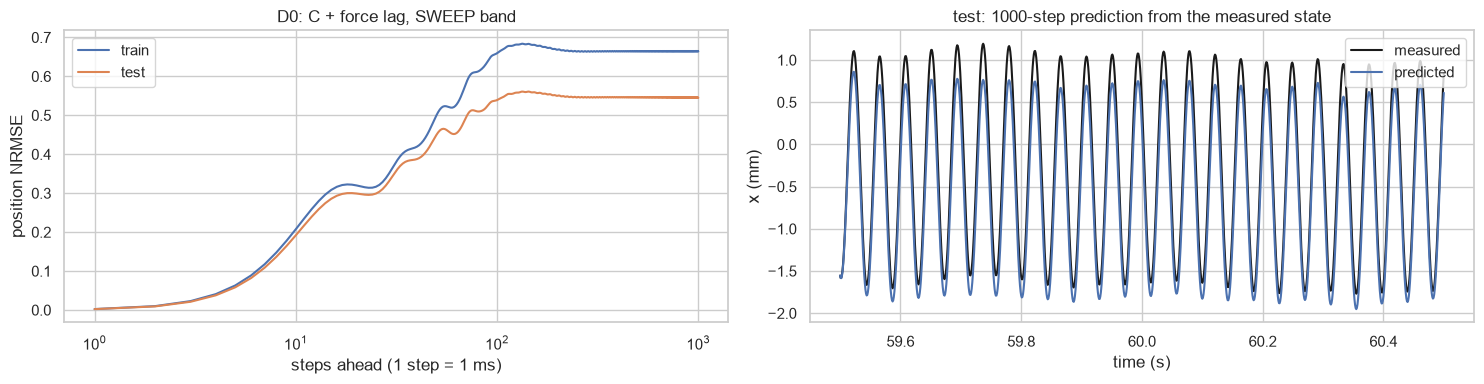

C:\Users\tommo\AppData\Local\Temp\ipykernel_46956\271814585.py:5: RuntimeWarning: overflow encountered in square
  return np.sqrt(np.mean(e ** 2, axis=0)) / np.std(d["x"][band])


train NRMSE at k = 1, 10, 100, 1000: 0.003, 0.251, nan, nan


C:\Users\tommo\AppData\Local\Temp\ipykernel_46956\271814585.py:5: RuntimeWarning: overflow encountered in square
  return np.sqrt(np.mean(e ** 2, axis=0)) / np.std(d["x"][band])


test  NRMSE at k = 1, 10, 100, 1000: 0.002, 0.222, nan, nan


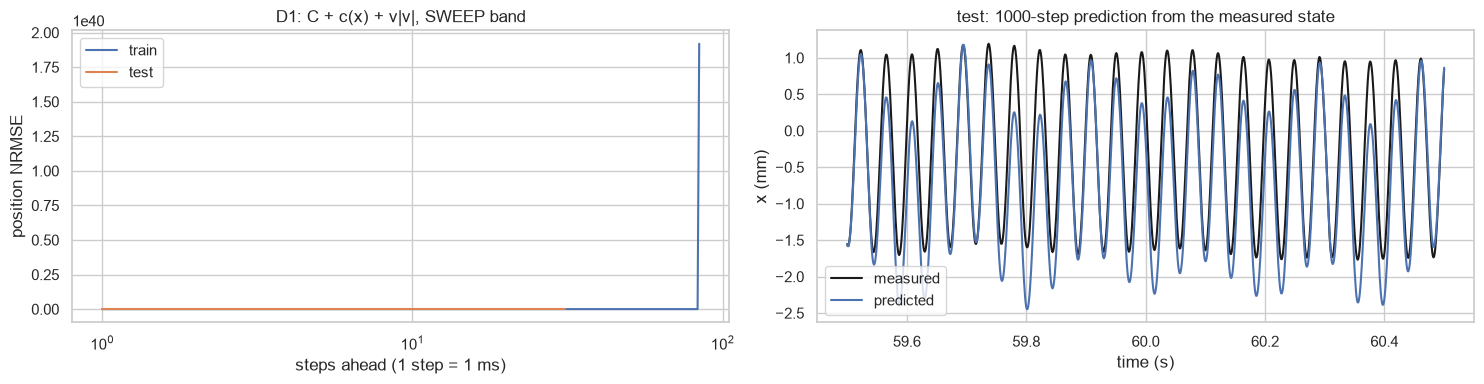

train NRMSE at k = 1, 10, 100, 1000: 0.003, 0.209, 1.025, 0.676
test  NRMSE at k = 1, 10, 100, 1000: 0.002, 0.192, 0.837, 0.556


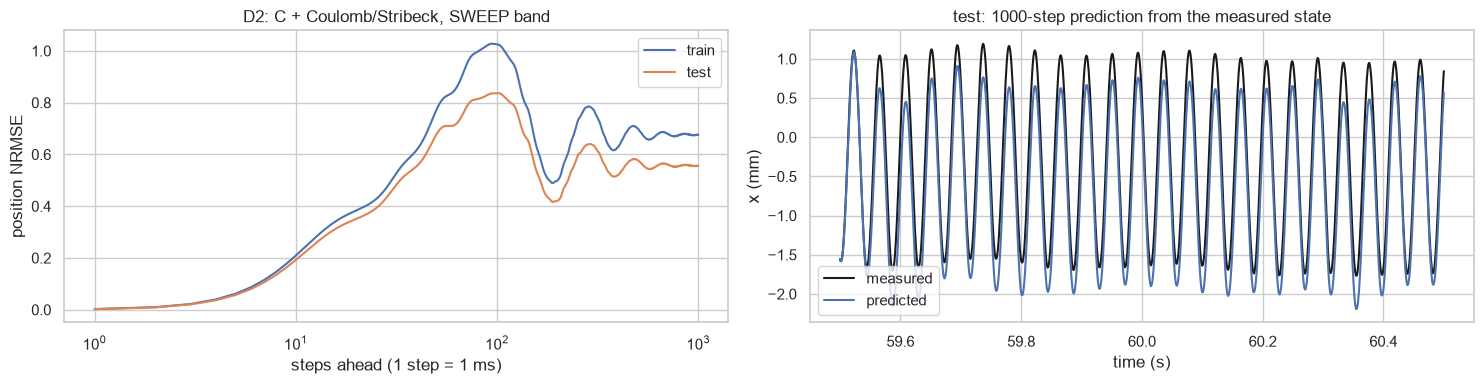

train NRMSE at k = 1, 10, 100, 1000: 0.002, 0.210, 0.816, 0.655
test  NRMSE at k = 1, 10, 100, 1000: 0.002, 0.194, 0.661, 0.528


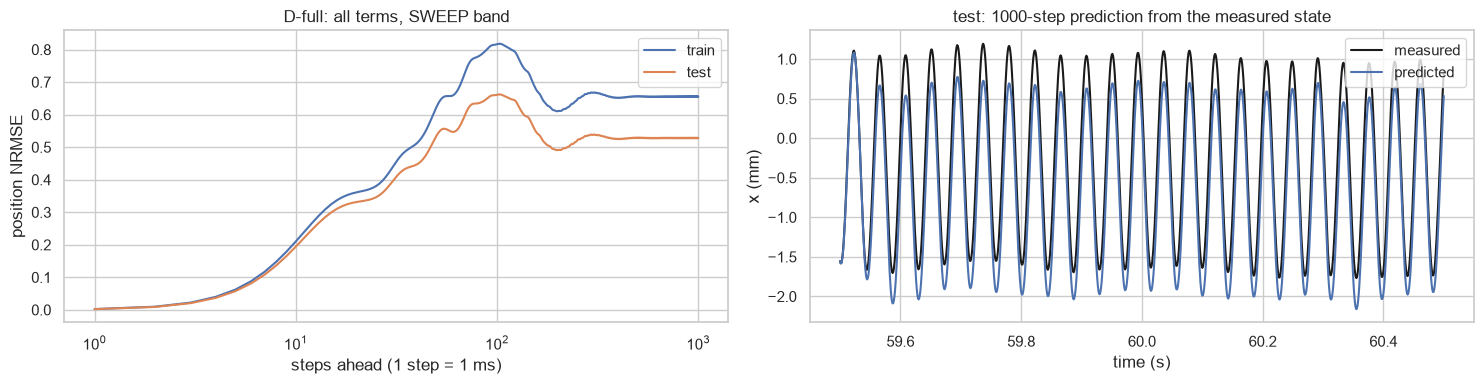


model    |   force std (N) |     NRMSE k=100 |    NRMSE k=1000
         |   train    test |   train    test |   train    test
C        |     362     344 |   0.781   0.640 |   0.715   0.587
D0       |     325     312 |   0.659   0.539 |   0.664   0.545
D1       |     333     312 |     nan     nan |     nan     nan
D2       |     324     309 |   1.025   0.837 |   0.676   0.556
D-full   |     314     299 |   0.816   0.661 |   0.655   0.528


In [14]:
def nrmse_curve_D(Fs, p, d, band, H=H_EVAL):
    "As nrmse_curve, with rollout_D."
    s = starts(d, band, H)
    e = rollout_D(Fs, p, d, s, H) - target(d, s, H)
    return np.sqrt(np.mean(e ** 2, axis=0)) / np.std(d["x"][band])


def evaluate_D(name, Fs, p, exp, band, H=H_EVAL):
    "As evaluate, with rollout_D. Left: NRMSE against horizon, train and test. Right: one H-step prediction on test."
    fig, ax = plt.subplots(1, 2, figsize=(15, 4))
    k = np.arange(1, H + 1)
    for split, d in DATA[exp].items():
        e = nrmse_curve_D(Fs, p, d, d[band], H)[1:]
        CURVES.append(dict(method=name, split=split, exp=exp, band=band, k=k, nrmse=e))
        sns.lineplot(x=k, y=e, ax=ax[0], label=split)
        print(f"{split:5s} NRMSE at k = 1, 10, 100, {H}: " + ", ".join(f"{e[j - 1]:.3f}" for j in (1, 10, 100, H)))
    ax[0].set(xscale="log", xlabel="steps ahead (1 step = 1 ms)", ylabel="position NRMSE", title=f"{name}, {band.upper()} band")
    d = DATA[exp]["test"]
    s0 = starts(d, d[band], H)
    s0 = s0[len(s0) // 2:][:1]                          # one start in the middle of the band
    t = d["t"][s0[0]:s0[0] + H + 1]
    sns.lineplot(x=t, y=target(d, s0, H)[0] * 1e3, ax=ax[1], label="measured", color="k")
    sns.lineplot(x=t, y=rollout_D(Fs, p, d, s0, H)[0] * 1e3, ax=ax[1], label="predicted")
    ax[1].set(xlabel="time (s)", ylabel="x (mm)", title=f"test: {H}-step prediction from the measured state")
    plt.tight_layout(); plt.show()


for key, D in DV.items():
    evaluate_D(LABELS[key], D["Fs"], D["p"], "chirpsched", "sweep", H=1000)

# summary against Model C; the NRMSE comes from the latest CURVES entry of each method
def curve_at(method, split, k):
    e = [c["nrmse"] for c in CURVES if c["method"] == method and c["split"] == split and c["band"] == "sweep"]
    return e[-1][k - 1] if e else np.nan

ROWS = [("C", "C: unequal magnets + Gamma(x)", BASE, p_C, 0.01, 0.05)] + \
       [(key, LABELS[key], D["names"], D["p"], D["v_c"], D["v_st"]) for key, D in DV.items()]
print(f"\n{'model':8s} | {'force std (N)':>15s} | {'NRMSE k=100':>15s} | {'NRMSE k=1000':>15s}")
print(f"{'':8s} | {'train':>7s} {'test':>7s} | {'train':>7s} {'test':>7s} | {'train':>7s} {'test':>7s}")
for key, method, names, p, v_c, v_st in ROWS:
    fs = [force_resid_std(names, p, v_c, v_st, s) for s in ("train", "test")]
    n100 = [curve_at(method, s, 100) for s in ("train", "test")]
    n1000 = [curve_at(method, s, 1000) for s in ("train", "test")]
    print(f"{key:8s} | {fs[0]:7.0f} {fs[1]:7.0f} | {n100[0]:7.3f} {n100[1]:7.3f} | {n1000[0]:7.3f} {n1000[1]:7.3f}")

## Validation

Each row starts all models (A, B, C, and D0 and D-full from Model D) from the same measured state and predicts the position over a short window, on data the fits did not use: other parts of the test scheduled chirp, a plain chirp, and two September runs (another day, other amplitudes). The NRMSE over the window is in the legend. The PRBS run moves ±16 mm, far outside the ±6 mm the models were fitted on, so that row is an extrapolation test.

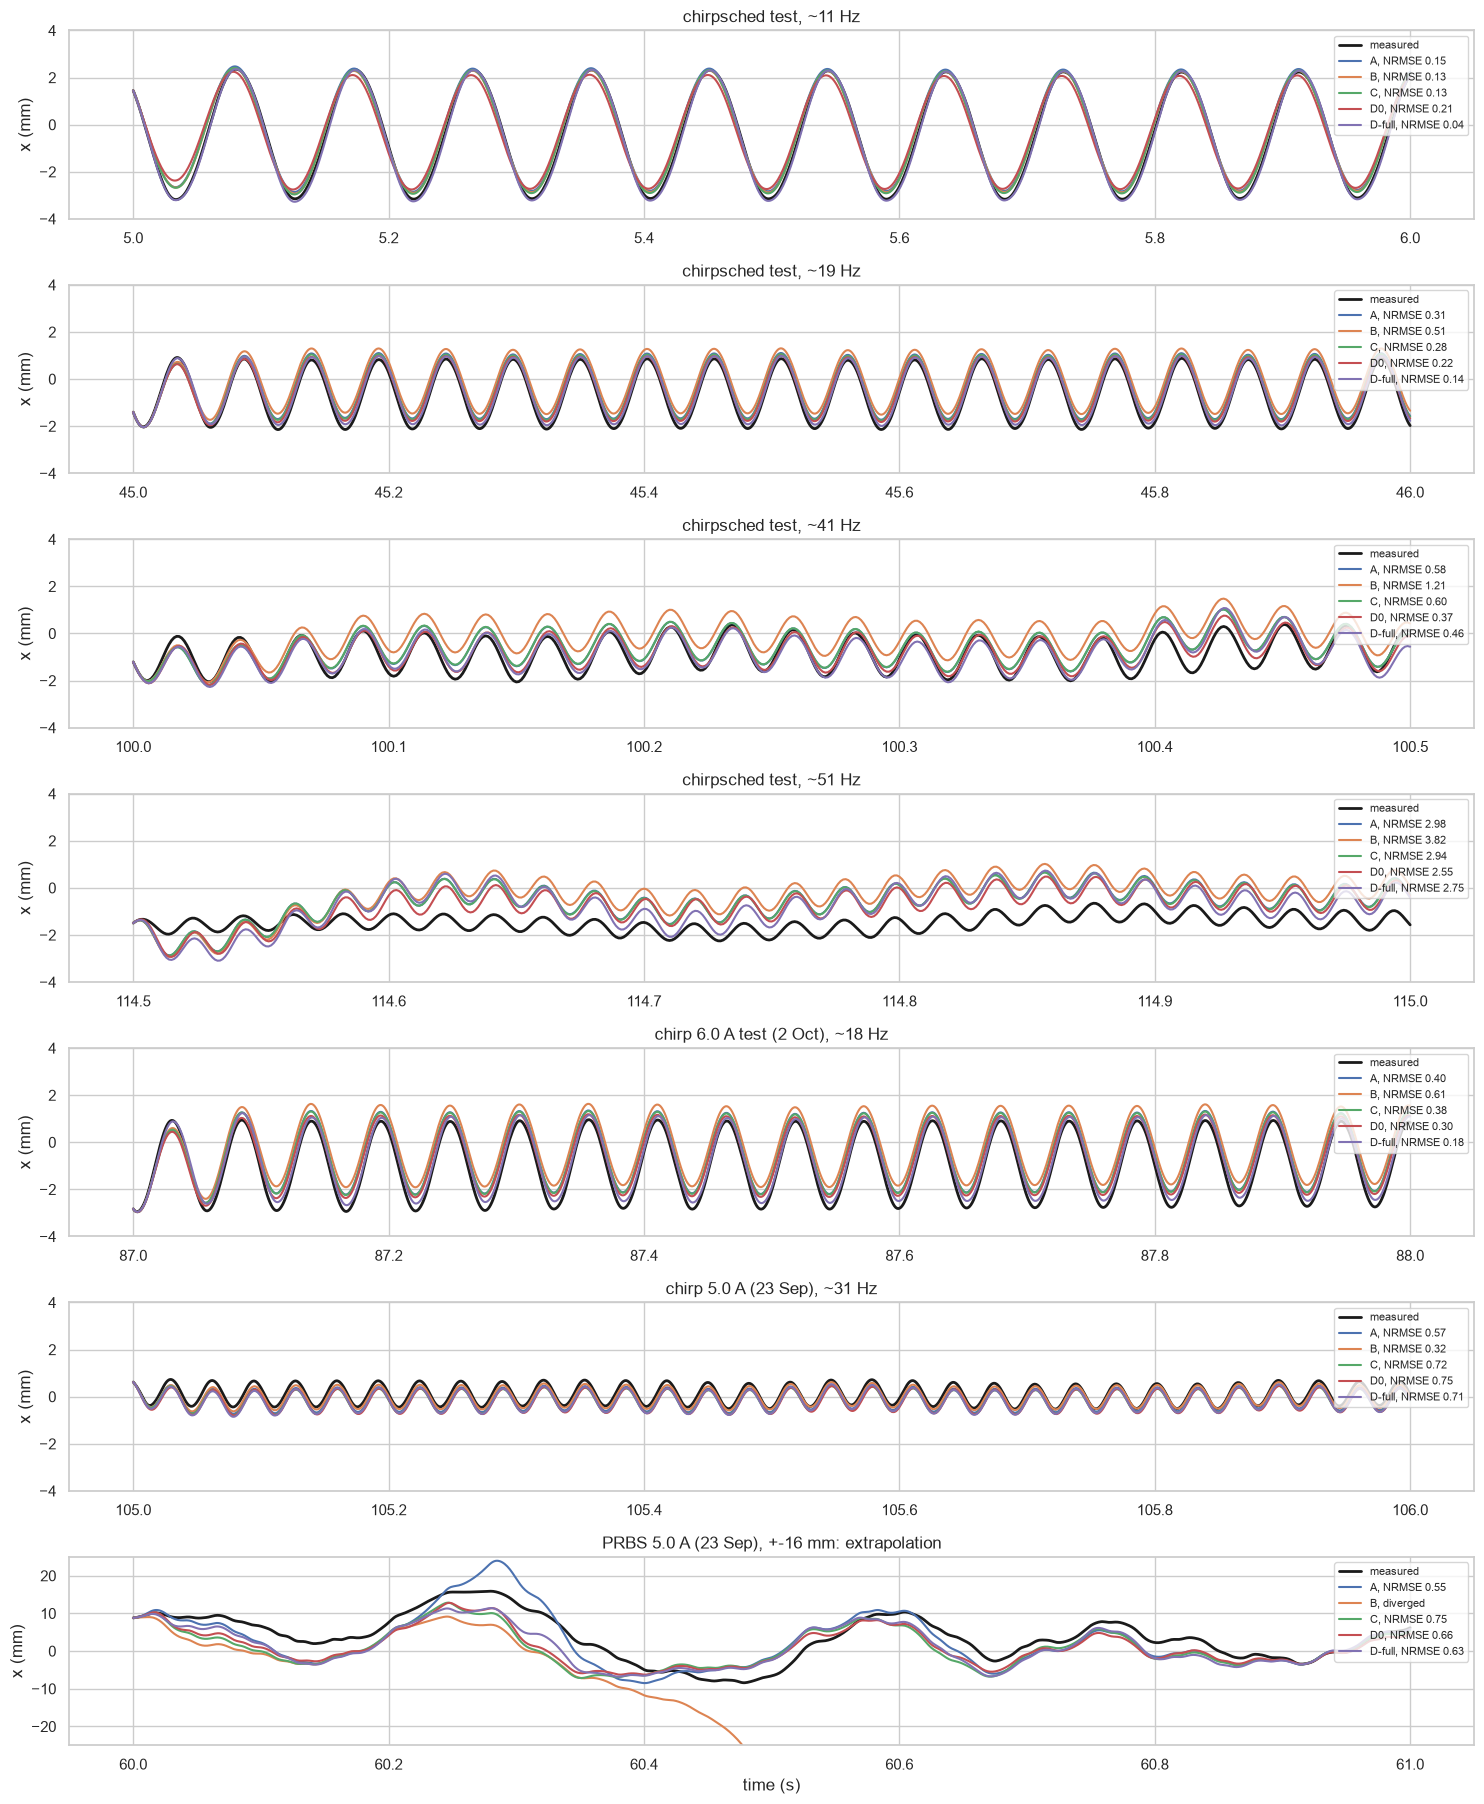

In [15]:
MODELS = [("A", poly3, p_p3, rollout), ("B", poly3_ds, p_B, rollout), ("C", magnets, p_C, rollout),   # (name, force, parameters, rollout)
          ("D0", DV["D0"]["Fs"], DV["D0"]["p"], rollout_D), ("D-full", DV["D-full"]["Fs"], DV["D-full"]["p"], rollout_D)]
SEP = lambda name: load(next(Path("data").glob(f"voice_coil_log_{name}_*.csv")))   # September logs in data/
VAL = [  # (label, data, start s, length s); chirp frequency f0 (f1/f0)^(t/T), checked against the current's zero crossings
    ("chirpsched test, ~11 Hz", DATA["chirpsched"]["test"], 5.0, 1.0),       # 10.7-10.9 Hz
    ("chirpsched test, ~19 Hz", DATA["chirpsched"]["test"], 45.0, 1.0),      # 19.0-19.2 Hz
    ("chirpsched test, ~41 Hz", DATA["chirpsched"]["test"], 100.0, 0.5),     # 41.4-41.7 Hz
    ("chirpsched test, ~51 Hz", DATA["chirpsched"]["test"], 114.5, 0.5),     # 50.9-51.2 Hz
    ("chirp 6.0 A test (2 Oct), ~18 Hz", DATA["chirp"]["test"], 87.0, 1.0),  # 18.3-18.9 Hz
    ("chirp 5.0 A (23 Sep), ~31 Hz", SEP("chirp_5.0A"), 105.0, 1.0),         # 30.7-31.7 Hz (this chirp ends at 50 Hz)
    ("PRBS 5.0 A (23 Sep), +-16 mm: extrapolation", SEP("prbs"), 60.0, 1.0),
]
Y_LIM, Y_LIM_PRBS = 4.0, 25.0                           # mm, y range of the chirp rows and of the PRBS row
fig, ax = plt.subplots(len(VAL), 1, figsize=(15, 2.6 * len(VAL)))
for a_, (label, d, t0, T) in zip(ax, VAL):
    s, H = np.array([np.searchsorted(d["t"], t0)]), int(round(T / TS))
    t, xm = d["t"][s[0]:s[0] + H + 1], target(d, s, H)[0]
    sns.lineplot(x=t, y=xm * 1e3, ax=a_, color="k", lw=2, label="measured")
    for name, Fs, p, roll in MODELS:
        with np.errstate(all="ignore"):
            xp = roll(Fs, p, d, s, H)[0]
        nr = np.sqrt(np.mean((xp - xm) ** 2)) / np.std(xm)
        sns.lineplot(x=t, y=np.where(np.isfinite(xp), xp, np.nan) * 1e3, ax=a_, lw=1.5, label=f"{name}, NRMSE {nr:.2f}" if np.isfinite(nr) else f"{name}, diverged")
    lim = Y_LIM_PRBS if label.startswith("PRBS") else Y_LIM
    a_.set(title=label, ylabel="x (mm)", ylim=(-lim, lim))
    a_.legend(loc="upper right", fontsize=8)
ax[-1].set(xlabel="time (s)")
plt.tight_layout(); plt.show()

## Kalman filter with Method A

Extended Kalman filter (EKF) on the Method A model, state $z = [x, \dot{x}]$, input $i$, measurement $y = x$:

$$z_{k+1} = f_{\text{RK4}}(z_k, i_k) + w_k, \qquad y_k = x_k + e_k$$

- Predict: one RK4 step of the model (the same `step` as the fits); covariance with the Jacobian $F = I + A T_s + (A T_s)^2/2$ of the model linearised at the current state.
- Process noise $w$: white acceleration noise with std `SIG_A`, set to the Method A acceleration residual on its own fit data. Measurement noise $e$: std `SIG_Y` (tuning knob).
- The velocity is the filter's own causal estimate, not the gradient of the (non-causal, zero-phase filtered) position.

**Single-step prediction error** $y_k - \hat{x}_{k|k-1}$ (the innovation: measurement minus the prediction made before that measurement is used), on the fit data (**TRAIN**, blue) and on two runs the fit did not use (**TEST**, red); the first `T_SETTLE` s are left out while the filter converges.
- Figure 1: error against time, with ±2 predicted std. Printed: RMS, NRMSE, the NRMSE of one RK4 step from the measured $(x, \dot{x})$ for reference, and innovation std / predicted std (1 when `SIG_A` and `SIG_Y` are consistent with the data).
- Figure 2: histogram of the error, with the normal density the filter predicts. A shifted or wider histogram on TEST than on TRAIN shows model error on new data.
- Figure 3: PSD of the error (Welch, 1 kHz), with the flat level of white noise at the predicted std. An optimal filter has white innovations; peaks show dynamics the model misses. Above 100 Hz the `load` low-pass has removed the content.

The measurements are the `load` signals (low-pass, notch and `TAU` shift applied offline), as in the fits; a real-time filter would get the causal, unfiltered position.

SIG_A = 7.02 m/s^2 (Method A residual), SIG_Y = 5.0 um
[TRAIN] chirpsched train (fit data)  RMS 10.14 um, NRMSE 8.27e-03 (from measured state 2.96e-03); innovation std / predicted std = 0.91
[TEST ] chirpsched test              RMS 9.59 um, NRMSE 7.70e-03 (from measured state 2.77e-03); innovation std / predicted std = 0.86
[TEST ] chirp 6.0 A test (2 Oct)     RMS 31.22 um, NRMSE 2.94e-03 (from measured state 9.35e-04); innovation std / predicted std = 2.73


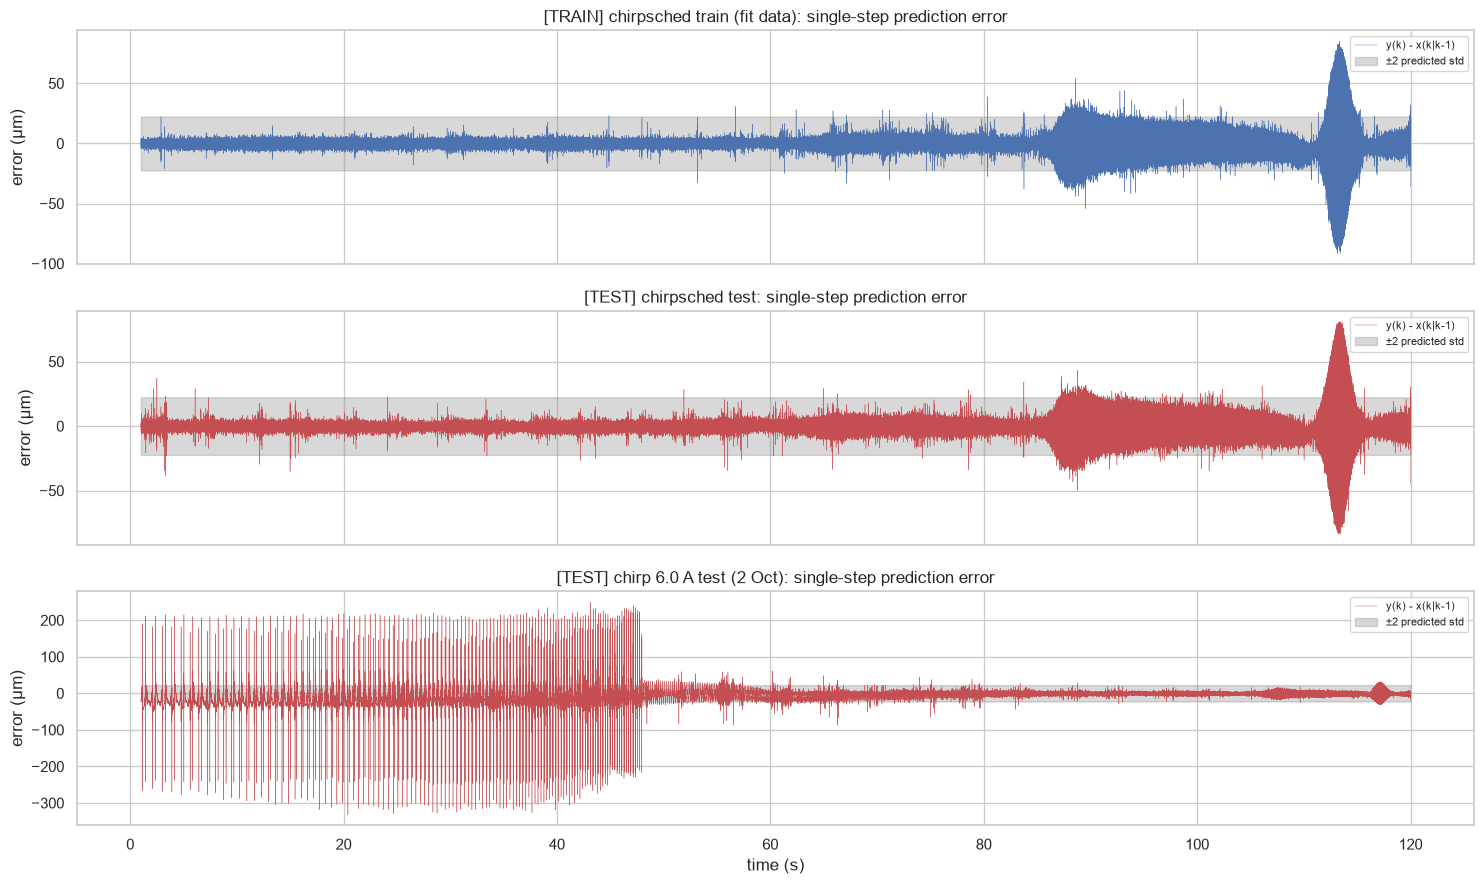

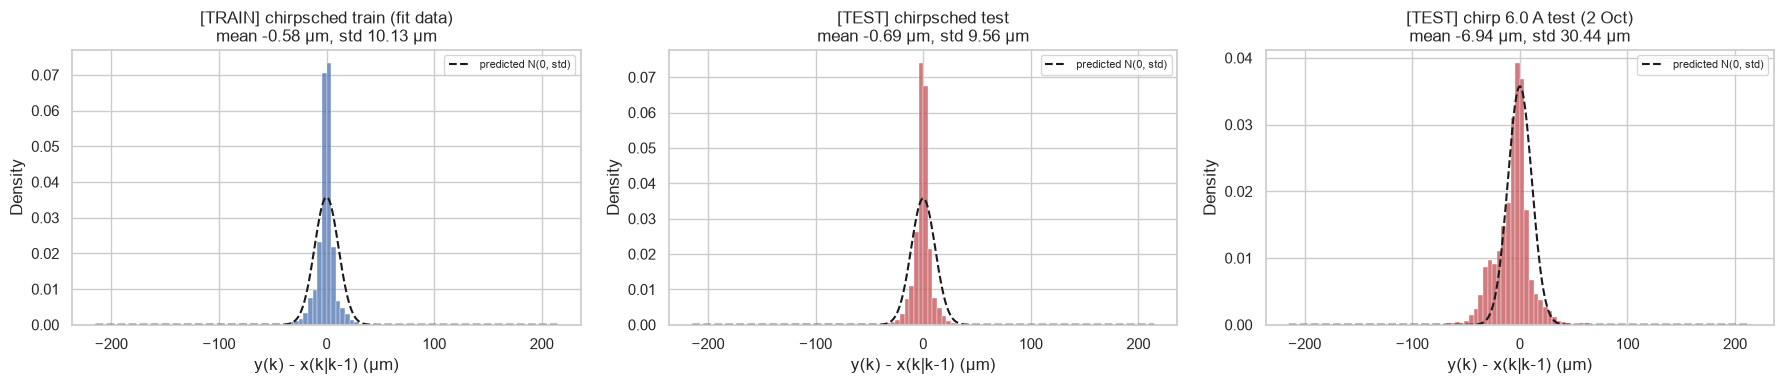

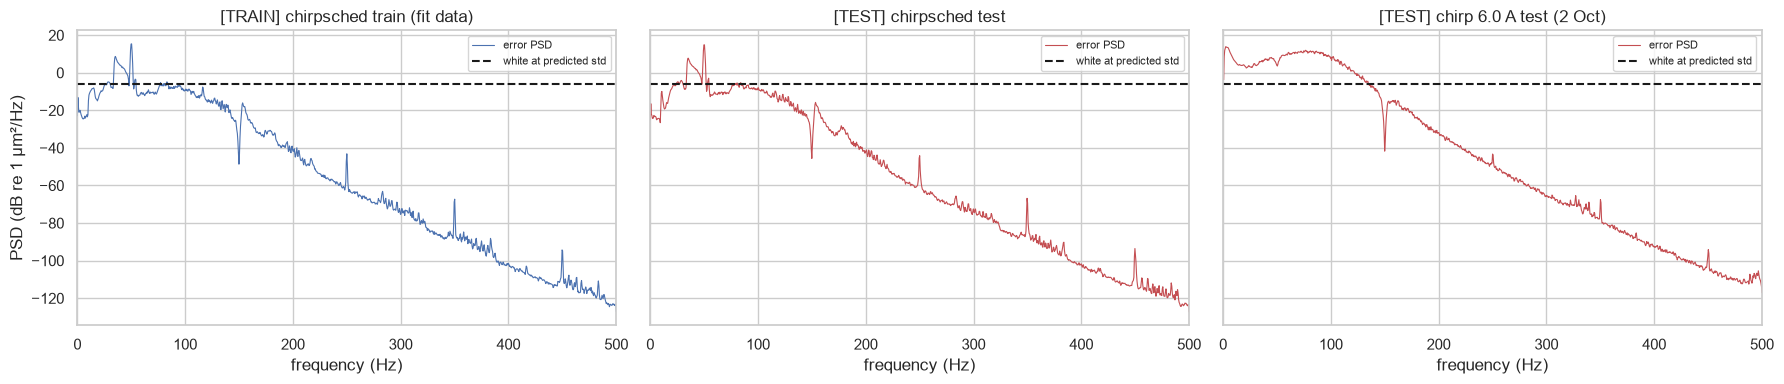

In [16]:
T_SETTLE = 1.0                                          # s left out at the start while the filter converges
SIG_Y = 5e-6                                            # m, measurement noise std (knob: laser after the load filters)
d, sel = DATA["chirpsched"]["train"], DATA["chirpsched"]["train"]["sweep"]
acc_A = lambda x, v, u: (p_p3[0] * u - p_p3[1] * v - poly3(x, u, p_p3[2:])) / M
SIG_A = np.std(d["a"][sel] - acc_A(d["x"][sel], d["v"][sel], d["i"][sel]))   # m/s^2, process noise: Method A residual on its fit data
print(f"SIG_A = {SIG_A:.3g} m/s^2 (Method A residual), SIG_Y = {SIG_Y * 1e6:.1f} um")


def ekf(Fs, p, d, sig_a, sig_y):
    "Extended Kalman filter, state [x, v], measurement x. Returns filtered x, v, one-step predicted x(k|k-1) and its innovation std."
    acc = lambda x, v, u: (p[0] * u - p[1] * v - Fs(x, u, p[2:])) / M
    q11, q12, q22, R = sig_a**2 * TS**4 / 4, sig_a**2 * TS**3 / 2, sig_a**2 * TS**2, sig_y**2   # white acceleration noise, discretized
    y, i = d["x"].tolist(), d["i"].tolist()             # python floats: the scalar loop runs several times faster
    n = len(y)
    xf, vf, xp, sp = (np.empty(n) for _ in range(4))
    x, v, p11, p12, p22 = y[0], 0.0, R, 0.0, 1e-4      # start at the first measurement, at rest, velocity std 1 cm/s
    for k in range(n):
        if k:   # predict: RK4 step of the model; covariance F P F' + Q with F = I + A Ts + (A Ts)^2 / 2
            u = i[k - 1]
            x, v = step(x, v, u, i[k] if FOH else u, acc)
            a21, a22 = -(Fs(x + 1e-7, u, p[2:]) - Fs(x - 1e-7, u, p[2:])) / 2e-7 / M, -p[1] / M   # A = [[0, 1], [a21, a22]]
            f11, f12 = 1 + a21 * TS**2 / 2, TS + a22 * TS**2 / 2
            f21, f22 = a21 * TS + a21 * a22 * TS**2 / 2, 1 + a22 * TS + (a21 + a22**2) * TS**2 / 2
            g11, g12, g21, g22 = f11 * p11 + f12 * p12, f11 * p12 + f12 * p22, f21 * p11 + f22 * p12, f21 * p12 + f22 * p22   # F P
            p11, p12, p22 = g11 * f11 + g12 * f12 + q11, g11 * f21 + g12 * f22 + q12, g21 * f21 + g22 * f22 + q22
        xp[k], S = x, p11 + R
        sp[k] = np.sqrt(S)
        k1, k2, e = p11 / S, p12 / S, y[k] - x           # update with the measured position
        x, v = x + k1 * e, v + k2 * e
        p11, p12, p22 = p11 - k1 * p11, p12 - k1 * p12, p22 - k2 * p12
        xf[k], vf[k] = x, v
    return xf, vf, xp, sp


# self-check: on noise-free output of the model itself, the one-step prediction must converge to it
_d = DATA["chirpsched"]["test"]
_x = rollout(poly3, p_p3, _d, np.array([0]), 3000)[0]
assert np.abs(ekf(poly3, p_p3, dict(x=_x, i=_d["i"][:3001]), SIG_A, SIG_Y)[2] - _x)[1000:].max() < 1e-6

# single-step prediction error e = y(k) - x(k|k-1) on the fit data (TRAIN) and two runs the fit did not use (TEST)
rms = lambda e: np.sqrt(np.mean(e**2))
RUNS = [("TRAIN", "chirpsched train (fit data)", DATA["chirpsched"]["train"]),
        ("TEST", "chirpsched test", DATA["chirpsched"]["test"]),
        ("TEST", "chirp 6.0 A test (2 Oct)", DATA["chirp"]["test"])]
ERR = []
fig, ax = plt.subplots(len(RUNS), 1, figsize=(15, 3 * len(RUNS)), sharex=True)
for a_, (split, label, d) in zip(ax, RUNS):
    xf, vf, xp, sp = ekf(poly3, p_p3, d, SIG_A, SIG_Y)
    band = d["t"] >= T_SETTLE
    e = (d["x"] - xp)[band]
    ERR.append((split, label, e, np.mean(sp[band])))
    s1 = np.flatnonzero(band)[:-1]                      # reference: one RK4 step from the measured (x, v)
    e_ms = d["x"][s1 + 1] - rollout(poly3, p_p3, d, s1, 1)[:, 1]
    print(f"[{split:5s}] {label:28s} RMS {rms(e) * 1e6:.2f} um, NRMSE {rms(e) / np.std(d['x'][band]):.2e} "
          f"(from measured state {rms(e_ms) / np.std(d['x'][band]):.2e}); innovation std / predicted std = {np.std(e) / np.mean(sp[band]):.2f}")
    color = "C0" if split == "TRAIN" else "C3"
    sns.lineplot(x=d["t"][band], y=e * 1e6, ax=a_, lw=0.3, color=color, label="y(k) - x(k|k-1)")
    a_.fill_between(d["t"][band], -2e6 * sp[band], 2e6 * sp[band], color="0.5", alpha=0.3, label="±2 predicted std")
    a_.set(ylabel="error (µm)", title=f"[{split}] {label}: single-step prediction error")
    a_.legend(loc="upper right", fontsize=8)
ax[-1].set(xlabel="time (s)")
plt.tight_layout(); plt.show()

# histogram of the single-step error, with the normal density the filter predicts (std = mean innovation std)
lim = max(np.percentile(np.abs(e), 99.5) for *_, e, _ in ERR) * 1e6
fig, ax = plt.subplots(1, len(ERR), figsize=(6 * len(ERR), 4), sharex=True)
for a_, (split, label, e, s) in zip(ax, ERR):
    sns.histplot(e * 1e6, ax=a_, stat="density", bins=np.linspace(-lim, lim, 101), color="C0" if split == "TRAIN" else "C3")
    g = np.linspace(-lim, lim, 400)
    a_.plot(g, np.exp(-0.5 * (g / (s * 1e6))**2) / (s * 1e6 * np.sqrt(2 * np.pi)), "k--", label="predicted N(0, std)")
    a_.set(xlabel="y(k) - x(k|k-1) (µm)", title=f"[{split}] {label}\nmean {e.mean() * 1e6:.2f} µm, std {e.std() * 1e6:.2f} µm")
    a_.legend(fontsize=8)
plt.tight_layout(); plt.show()

# PSD of the single-step error (Welch, fs = 1 kHz). An optimal filter has white innovations: flat at 2 std^2 / fs (one-sided);
# peaks show structure the model misses (e.g. the 35.5 Hz laser-mount mode); above 100 Hz the load low-pass removes the content
fig, ax = plt.subplots(1, len(ERR), figsize=(6 * len(ERR), 4), sharey=True)
for a_, (split, label, e, s) in zip(ax, ERR):
    f, P = signal.welch(e * 1e6, fs=1 / TS, window="hann", nperseg=2048, noverlap=1024, detrend="constant", scaling="density")
    sns.lineplot(x=f, y=10 * np.log10(P + 1e-20), ax=a_, lw=0.8, color="C0" if split == "TRAIN" else "C3", label="error PSD")
    a_.axhline(10 * np.log10(2 * (s * 1e6)**2 * TS), color="k", ls="--", label="white at predicted std")
    a_.set(xlim=(0, 1 / (2 * TS)), xlabel="frequency (Hz)", ylabel="PSD (dB re 1 µm²/Hz)", title=f"[{split}] {label}")
    a_.legend(fontsize=8)
plt.tight_layout(); plt.show()